In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

In [2]:
flopp_flopp_e_pivot = pd.read_csv('processed_data/flopp_flopp_e_pivot.csv')

In [3]:
flopp_flopp_e_pivot.query('file_name == "R 16. Black Rubber Paving.CSV"')

,Unnamed: 0,file_name,polymer,data_source,674.9918,676.9203,678.8489,680.7775,682.706,684.6345,...,3982.452,3984.38,3986.309,3988.237,3990.166,3992.094,3994.023,3995.951,3997.88,3999.809


In [81]:
spectra_data_bg = pd.read_csv('OPTIR/Pilot_Phase_Field_Samples_subs2/data_background.csv')
del spectra_data_bg['Unnamed: 0']
bg_id = spectra_data_bg['id']

In [136]:
spectra_data = pd.read_csv('OPTIR/Pilot_Phase_Field_Samples_subs2/data_all_spectral.csv')
spectra_data = pd.read_csv('OPTIR/Pilot_Phase_Field_Samples_subs2/data_non_background.csv')
del spectra_data['Unnamed: 0']

In [137]:
spectra_data.query('id =="FHS_Run1_24"')

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2994.0,2996.0,2998.0,3000.0,3002.0,3004.0,id,school,run,sample_id


In [40]:
#spectra_data.iloc[242:243,:-4].columns[np.where(np.isnan(np.float64(spectra_data.iloc[242,:-4])))[0]]
spectra_data.loc[232:232,spectra_data.iloc[232:232,:-4].columns[np.where(np.isnan(np.float64(spectra_data.iloc[232,:-4])))[0]]] = 0#[np.isnan(np.float64(spectra_data.iloc[242,:-4]))]


In [41]:
np.where(np.isnan(np.float64(spectra_data.iloc[232,:-4])))[0].shape

(0,)

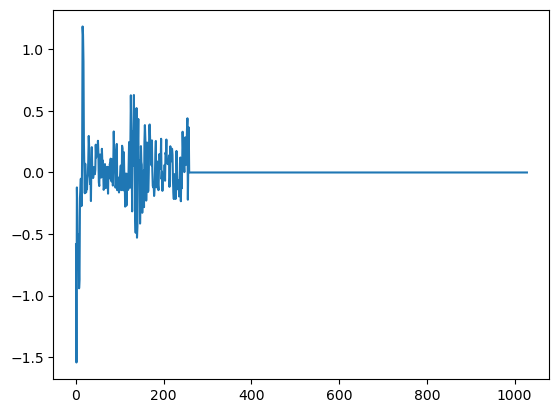

In [42]:
plt.plot(np.float64(spectra_data.iloc[232,:-4]))

In [138]:
spectra_data_long = spectra_data.iloc[:, :-3].melt(id_vars='id')#
spectra_data_long.iloc[:,1:] = spectra_data_long.iloc[:,1:].astype('float32')

spectra_data_long.columns = ['file_name','wavelength','intensity']
spectra_data_long['polymer'] = ''
spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=674.9918, max_wl=3999.809,n=1725)
spectra_data_int = spectra_data_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [139]:
wl_list = np.float64(spectra_data_int.columns[1:])
wl_list_1 = np.float64(spectra_data.columns[:-4])
wl_list_2 = np.float64(spectra_data_int.columns[1:])

idx_range = np.logical_or(
    np.logical_and(
        wl_list_2 > wl_list_1.min(),
        wl_list_2 < np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-4])))])).min()-1, #-1
    ),
    np.logical_and(
        wl_list > np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-4])))])).max()+1,
        wl_list < wl_list_1.max(),
    )
)

In [140]:
import pickle 
filename = 'idx_range.sav'
pickle.dump(idx_range, open(filename, 'wb'))

In [388]:
x_train = flopp_flopp_e_pivot.iloc[:,4:].to_numpy()
x_train = -x_train[:,idx_range]
x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
x_train_diff = np.diff(x_train)
x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
y_train = flopp_flopp_e_pivot.iloc[:,2]


In [142]:
spectra_data_np = np.float32(spectra_data_int.iloc[:,1:].to_numpy())
spectra_data_np_norm = (spectra_data_np[:,idx_range] - spectra_data_np[:,idx_range].mean(1)[:,None]) / spectra_data_np[:,idx_range].std(1)[:,None]
spectra_data_np_norm = spectra_data_np_norm #/ (spectra_data_np_norm.shape[0] ** 0.5)

spectra_data_diff = np.diff(spectra_data_np_norm)
spectra_data_diff = (spectra_data_diff - spectra_data_diff.mean(1)[:,None]) / spectra_data_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)


In [143]:
wl_2700_3000 = np.logical_and(wl_list[idx_range] > 2700,
                                    wl_list[idx_range] < 3000)

spectra_data_np_norm_2700_3000 = spectra_data_np_norm[:, wl_2700_3000]
spectra_data_np_norm_2700_3000 = (spectra_data_np_norm_2700_3000 - spectra_data_np_norm_2700_3000.mean(1)[:,None])

std_2700_3000 = spectra_data_np_norm_2700_3000.std(1)

std_2700_3000.min()

0.0029467095

In [144]:
clf_diff = pickle.load(open('log_diff_classifier.sav', 'rb'))
kmeans = pickle.load(open('knn_distance.sav', 'rb'))

In [145]:
pred_polymers_hqi_diff = corr_matching(x_train_diff, y_train, spectra_data_diff, r_min=0.7)[0].to_numpy()
pred_hqi_diff = corr_matching(x_train_diff, y_train, spectra_data_diff, r_min=0.7)[1]#.to_numpy()
best_match_diff = corr_matching(x_train_diff, y_train, spectra_data_diff, r_min=0.7)[0].index.to_numpy()

In [146]:
pred_prob_diff = clf_diff.predict_proba(spectra_data_diff).max(1) 
pred_poly_diff = clf_diff.predict(spectra_data_diff)

In [147]:
kk_centers = kmeans.cluster_centers_
distance_center_k_ = pairwise_distances(kk_centers, spectra_data_diff).min(0)
corr_center_k_ = np.corrcoef(np.concatenate([kk_centers, spectra_data_diff]))[19:,:19].max(1)
corr_center_k_ = np.corrcoef(np.concatenate([kk_centers, spectra_data_diff]))[19:,:19].max(1)

In [148]:
rejected = ~((distance_center_k_<27) * (std_2700_3000 > 0.06))

## Background exercise 

In [105]:
print(1-np.mean([i not in spectra_data_int.loc[rejected,'file_name'].to_numpy() for i in bg_id]))
spectra_data_int.loc[rejected,'file_name'].iloc[[144, 658, 686]]

0.9980353634577603


151    Daycroft_Run2_53
699         IAO_Run2_15
728         IAO_Run2_41
Name: file_name, dtype: object

In [108]:
np.where([i not in spectra_data_int.loc[rejected,'file_name'].to_numpy() for i in bg_id])

(array([220]),)

In [110]:
len([i not in spectra_data_int.loc[rejected,'file_name'].to_numpy() for i in bg_id])

509

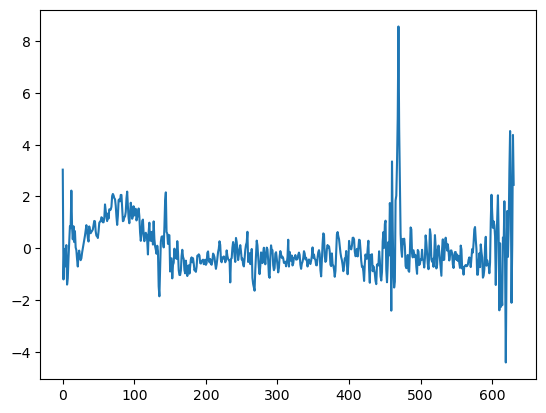

In [109]:
plt.plot(spectra_data_np_norm[[220], 1:].T)

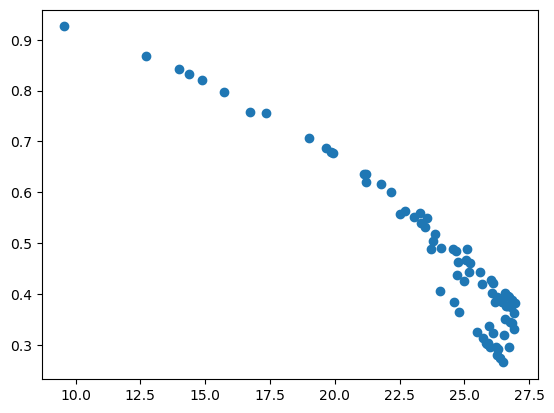

In [149]:
plt.scatter(distance_center_k_[distance_center_k_<27],corr_center_k_[distance_center_k_<27])

In [215]:
distance_center_k_[pred_poly_diff == 'Polyethylene Terephthalate']

array([30.03184522, 23.72357707, 28.64712435, 28.92512789, 30.22307438,
       29.25573769, 29.52735714, 30.54258427])

In [216]:
std_2700_3000[pred_poly_diff == 'Polyethylene Terephthalate']

array([0.17503686, 0.07026447, 0.21553536, 0.08346467, 0.18261175,
       0.05303277, 0.20199451, 0.26417524], dtype=float32)

In [220]:
pred_polymers_hqi_diff[pred_poly_diff == 'Polyethylene Terephthalate']

array(['Polyethylene Terephthalate', 'Polyvinyl Chloride', 'Rubber',
       'Rubber', 'Polyethylene Terephthalate', 'Rubber', 'Cotton',
       'Rubber'], dtype=object)

In [150]:
sum(distance_center_k_<27)

77

(array([1., 0., 0., 0., 0., 0., 0., 2., 2., 3.]),
 array([23.72357707, 24.40547779, 25.08737851, 25.76927923, 26.45117995,
        27.13308067, 27.81498139, 28.49688211, 29.17878283, 29.86068355,
        30.54258427]),
 <BarContainer object of 10 artists>)

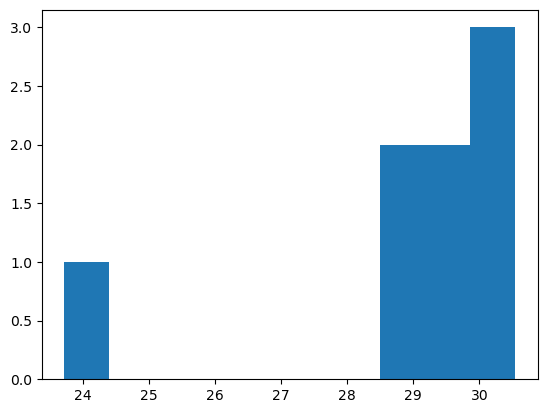

In [151]:
plt.hist(distance_center_k_[pred_poly_diff == 'Polyethylene Terephthalate'])

In [229]:
flopp_flopp_e_pivot

,Unnamed: 0,file_name,polymer,data_source,674.9918,676.9203,678.8489,680.7775,682.706,684.6345,...,3982.452,3984.38,3986.309,3988.237,3990.166,3992.094,3994.023,3995.951,3997.88,3999.809
0,0,ABS 1. Black Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp_e,-1.652339,-1.716827,-1.864428,-1.967062,-2.049846,-2.187845,...,0.478590,0.474398,0.473947,0.481465,0.479542,0.479669,0.483015,0.476869,0.475167,0.482083
1,1,ABS 1. Orange LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-2.558419,-2.617344,-2.647565,-2.732447,-2.850790,-2.988317,...,0.637547,0.634108,0.648501,0.656325,0.655386,0.664971,0.665558,0.651044,0.645997,0.654486
2,2,ABS 10. Brown LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-2.265023,-2.309608,-2.374530,-2.446580,-2.540923,-2.695691,...,0.832796,0.829453,0.840934,0.849702,0.846336,0.842218,0.841419,0.842121,0.844761,0.844858
3,3,ABS 11. Black LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-2.061761,-2.108204,-2.142853,-2.220130,-2.299527,-2.437295,...,0.696705,0.688823,0.696865,0.706376,0.712737,0.715482,0.715432,0.705735,0.699177,0.700378
4,4,ABS 12. White LEGO Fragment.CSV,Acrylonitrile Butadiene Styrene,flopp,-4.333531,-4.334141,-4.328848,-4.340096,-4.405816,-4.480118,...,0.439976,0.435928,0.447634,0.458499,0.456927,0.451888,0.451876,0.449256,0.447064,0.447839
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375,375,R 5. Black Michelin Tire Fragment.CSV,Rubber,flopp,-0.911333,-0.947815,-0.963645,-0.973925,-1.003195,-1.033317,...,0.531372,0.531329,0.529879,0.528860,0.529708,0.530439,0.531653,0.532614,0.533305,0.532427
376,376,R 6. Black Bike Tire Fragment.CSV,Rubber,flopp,-0.516341,-0.546198,-0.556689,-0.539175,-0.577721,-0.618201,...,0.379056,0.370742,0.381748,0.391027,0.390442,0.384034,0.387614,0.391387,0.387133,0.387726
377,377,R 8. White Bike Tire Fragment.CSV,Rubber,flopp,-2.848426,-2.819902,-2.796277,-2.773726,-2.762003,-2.737744,...,0.609851,0.608619,0.608971,0.607739,0.606495,0.605651,0.604783,0.603891,0.603293,0.601322
378,378,R 9. Grey Rubber Fragment.CSV,Rubber,flopp,-2.590038,-2.461975,-2.441007,-2.419963,-2.408041,-2.403519,...,0.501423,0.502715,0.504578,0.506349,0.508526,0.508933,0.508087,0.506785,0.506107,0.504591


In [412]:
flopp_flopp_e_pivot.groupby('polymer').count()

,Unnamed: 0,file_name,data_source,674.9918,676.9203,678.8489,680.7775,682.706,684.6345,686.5631,...,3982.452,3984.38,3986.309,3988.237,3990.166,3992.094,3994.023,3995.951,3997.88,3999.809
polymer,,,,,,,,,,,,,,,,,,,,,
Acrylic,6,6,6,6,6,6,6,6,6,6,...,6,6,6,6,6,6,6,6,6,6
Acrylonitrile Butadiene Styrene,15,15,15,15,15,15,15,15,15,15,...,15,15,15,15,15,15,15,15,15,15
Cellulose Acetate,2,2,2,2,2,2,2,2,2,2,...,2,2,2,2,2,2,2,2,2,2
Cotton,26,26,26,26,26,26,26,26,26,26,...,26,26,26,26,26,26,26,26,26,26
Ethylene Acrylic Acid,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Polyamide,18,18,18,18,18,18,18,18,18,18,...,18,18,18,18,18,18,18,18,18,18
Polycarbonate,9,9,9,9,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
Polyethylene,67,67,67,67,67,67,67,67,67,67,...,67,67,67,67,67,67,67,67,67,67
Polyethylene Adipate,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [227]:
poly_list = ['Polyethylene Terephthalate', 'Polyethylene', 'Polyamide', 'Cellulose Acetate', 'Polyethylene Vinyl Acetate', 'Rubber']

In [400]:
poly_list = ['Polystyrene', 'Polyurethane']

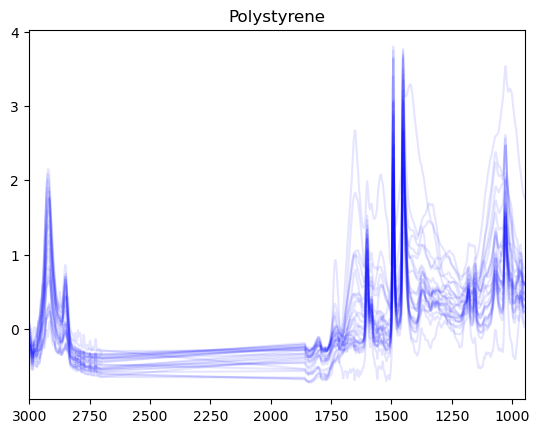

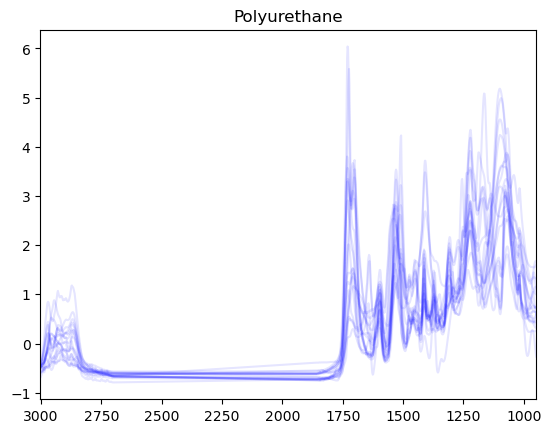

In [401]:
for p in poly_list:
    _ = plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].T, label=poly,c='b',alpha=.1)
    _ = plt.xlim((wl_list_2[idx_range].max(), wl_list_2[idx_range].min()))
    _ = plt.title(p)
    _ = plt.show()
#_ = plt.plot(spectra_data_np_norm[pred_poly_diff == 'Polyethylene Terephthalate',:][[1,2,3],:].T)

In [404]:
flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].mean(0)

948.8456   -0.484004
950.7742   -0.482610
952.7028   -0.486929
954.6312   -0.504416
956.5598   -0.539414
              ...   
2995.035    0.242200
2996.964    0.195119
2998.892    0.166873
3000.821    0.170233
3002.749    0.168596
Length: 632, dtype: float64

{'Acrylic',
 'Acrylonitrile Butadiene Styrene',
 'Cellulose Acetate',
 'Cotton',
 'Ethylene Acrylic Acid',
 'Polyamide',
 'Polycarbonate',
 'Polyethylene',
 'Polyethylene Adipate',
 'Polyethylene Terephthalate',
 'Polyethylene Vinyl Acetate',
 'Polylactic acid',
 'Polymethyl Methacrylate',
 'Polypropylene',
 'Polystyrene',
 'Polyurethane',
 'Polyvinyl Chloride',
 'Rubber',
 'Silicone Rubber'}

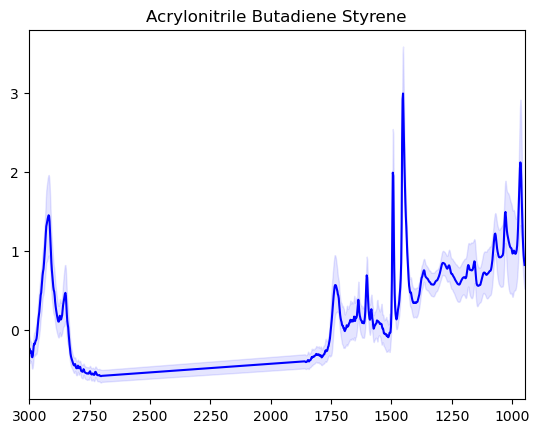

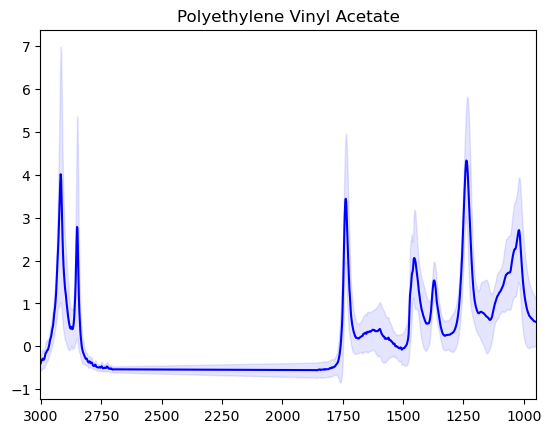

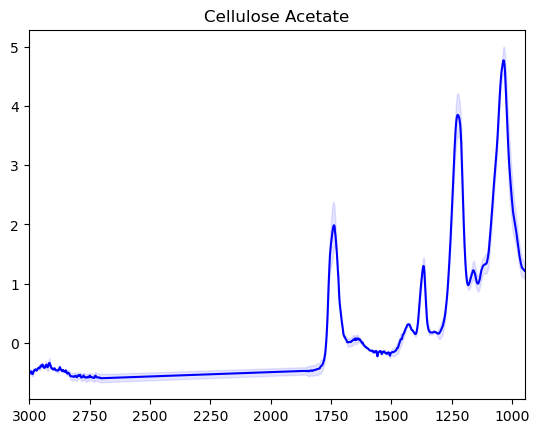

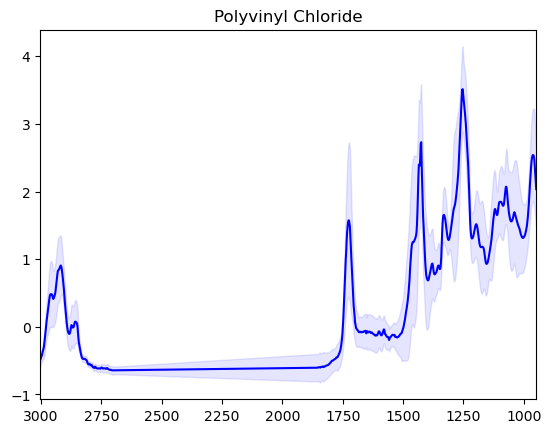

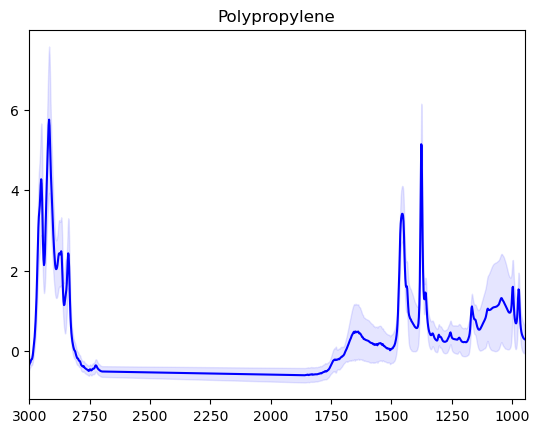

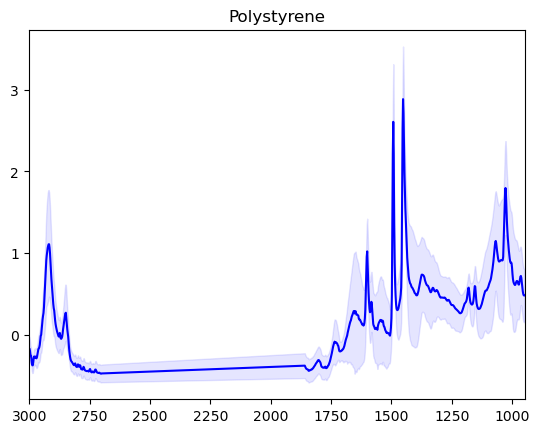

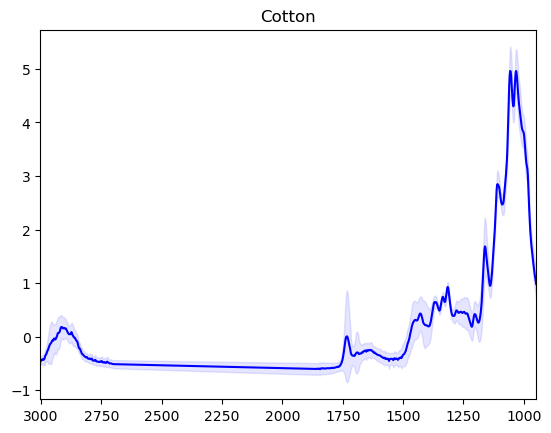

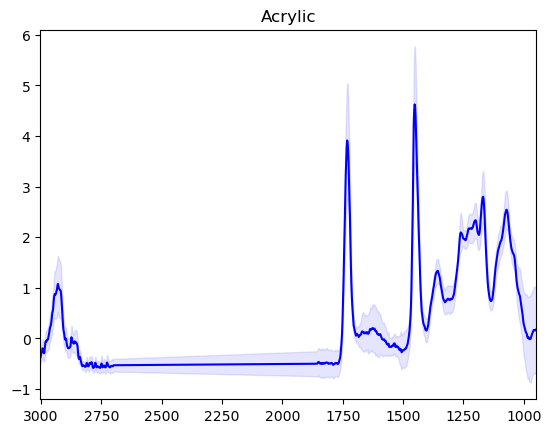

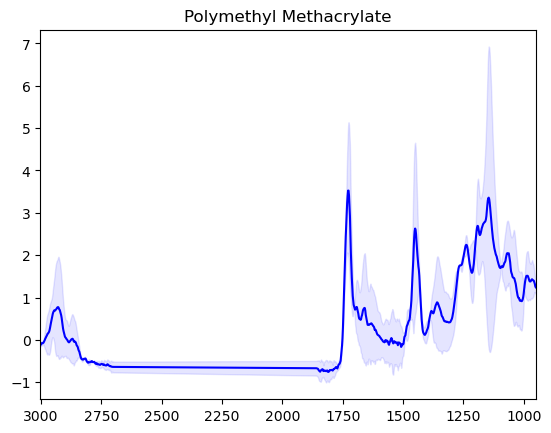

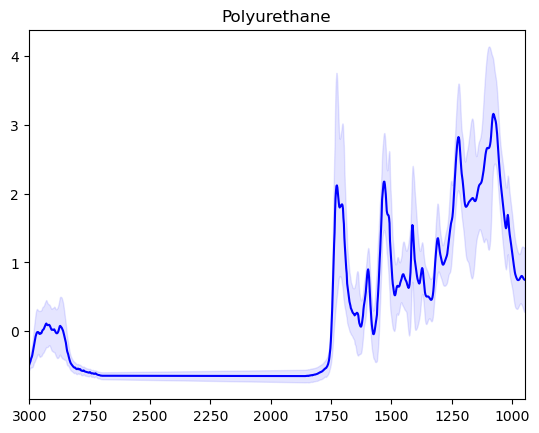

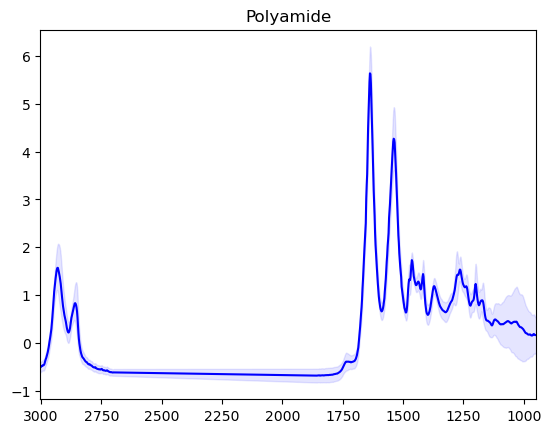

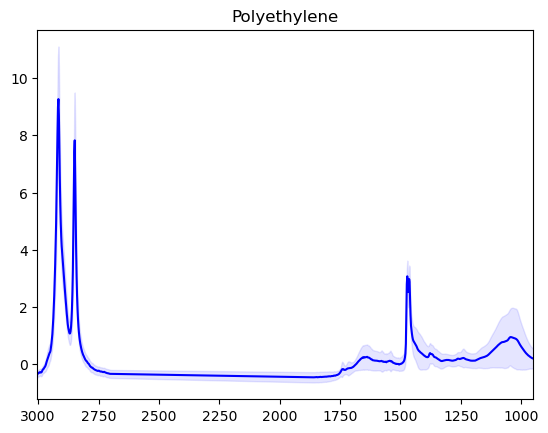

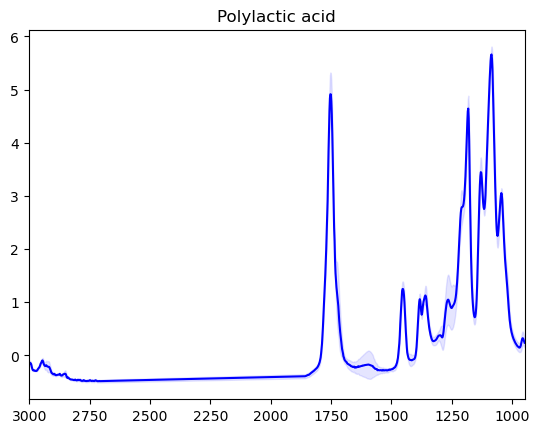

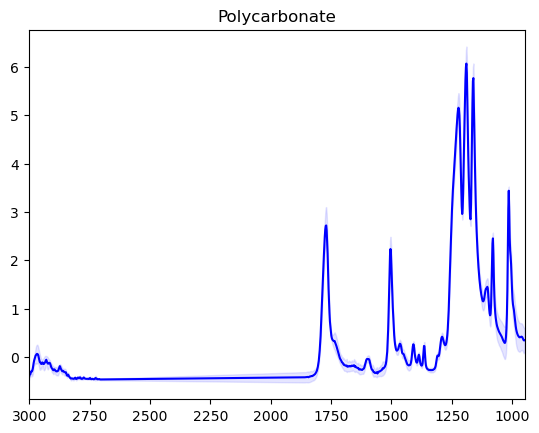

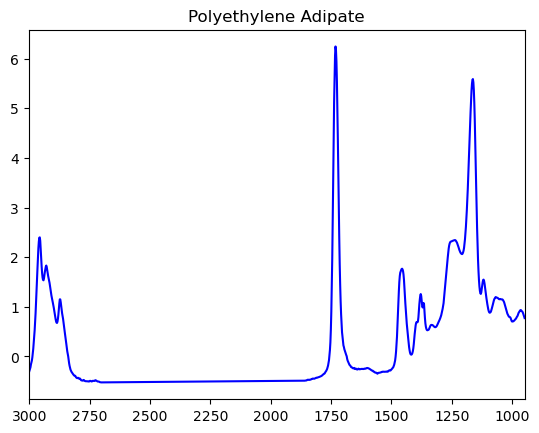

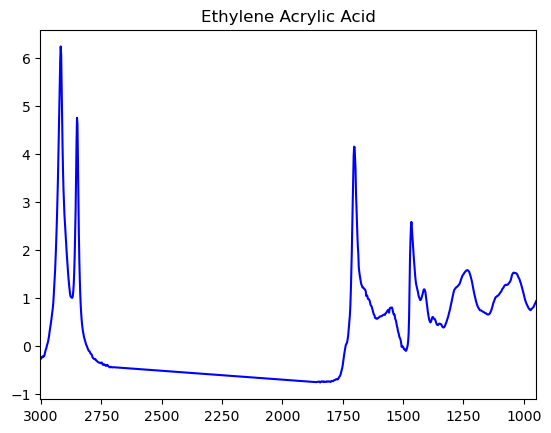

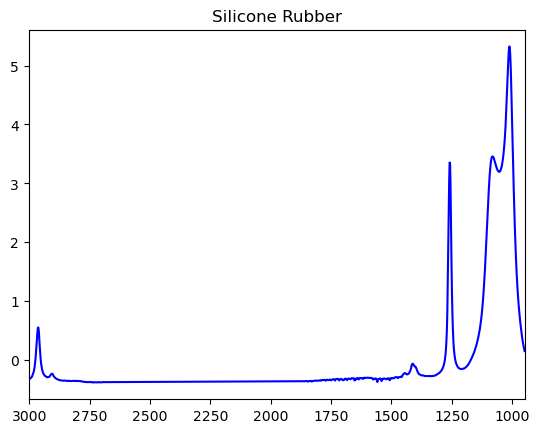

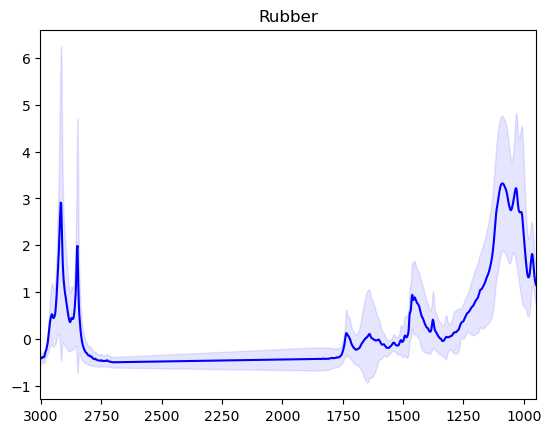

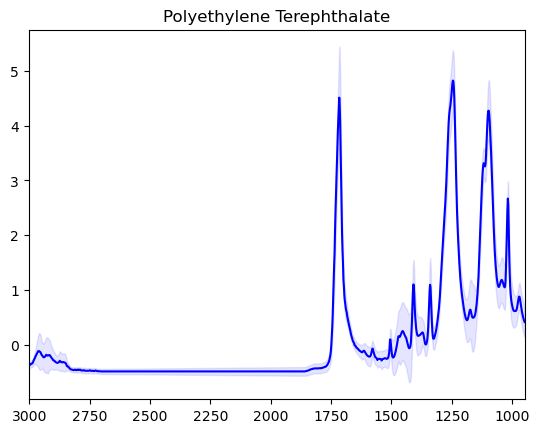

In [411]:
for p in set(flopp_flopp_e_pivot['polymer']):
    _ = plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].mean(0), label=poly,c='b')
    _ = plt.fill_between(wl_list_2[idx_range],
                 -flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].mean(0) - flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].std(0),
                 -flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].mean(0) + flopp_flopp_e_pivot.query('polymer == @p').iloc[:,4:].loc[:,idx_range].std(0),
                     color='b', alpha=.1)
    _ = plt.xlim((wl_list_2[idx_range].max(), wl_list_2[idx_range].min()))
    _ = plt.title(p)
    _ = plt.savefig('Pilot_Phase_Field_Samples_results2/plots_flopp/' + p +'.png')
    _ = plt.show()
#_ = plt.plot(spectra_data_np_norm[pred_poly_diff == 'Polyethylene Terephthalate',:][[1,2,3],:].T)

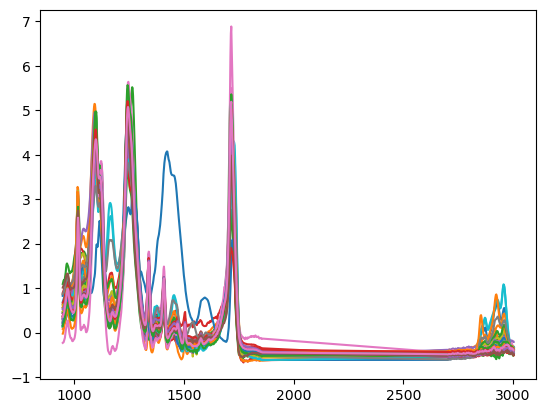

In [153]:
_ = plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.query('polymer == "Polyethylene Terephthalate"').iloc[:,4:].loc[:,idx_range].T, label=poly)



In [154]:
rejected = ~((distance_center_k_ < 27) * (std_2700_3000 > 0.06))
rejected_non_sig = ~((distance_center_k_ < 27) * (std_2700_3000 < 0.06))

In [155]:
sum(pred_polymers_hqi_diff[~rejected] == pred_poly_diff[~rejected])

25

In [375]:
pred_polymers_hqi_diff[~rejected_non_sig]

array(['Rubber', 'Cotton', 'Cotton', 'Cotton', 'Cotton', 'Cotton',
       'Cotton', 'Cotton', 'Cotton', 'Cotton', 'Cotton', 'Cotton',
       'Cotton', 'Cotton', 'Cotton', 'Cotton', 'Rubber', 'Cotton',
       'Rubber', 'Rubber', 'Cotton', 'Cotton', 'Rubber'], dtype=object)

id           ICB_Run3_42
school               ICB
run                 Run3
sample_id             42
Name: 283, dtype: object


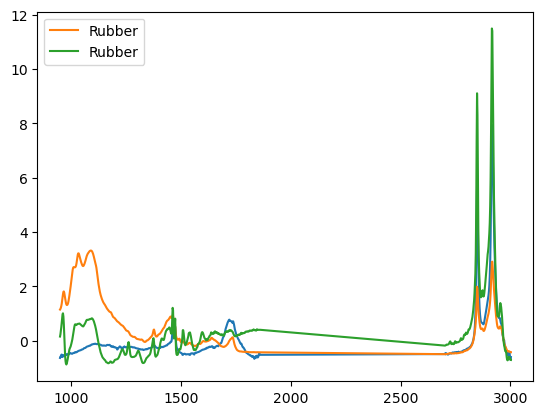

id           ICB_Run3_77
school               ICB
run                 Run3
sample_id             77
Name: 312, dtype: object


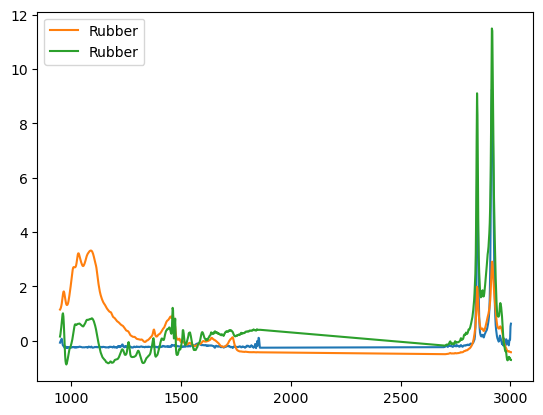

id           ICB_Run3_72
school               ICB
run                 Run3
sample_id             72
Name: 308, dtype: object


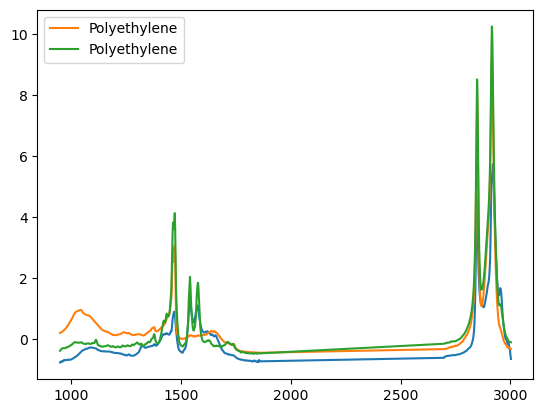

id           Daycroft_Run3_22
school               Daycroft
run                      Run3
sample_id                  22
Name: 17, dtype: object


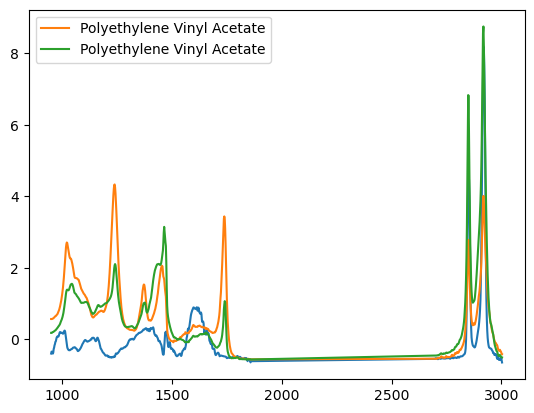

id           ICB_Run3_69
school               ICB
run                 Run3
sample_id             69
Name: 305, dtype: object


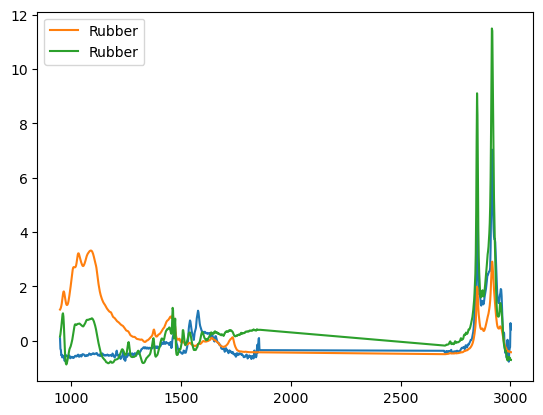

id           ICB_Run3_39
school               ICB
run                 Run3
sample_id             39
Name: 282, dtype: object


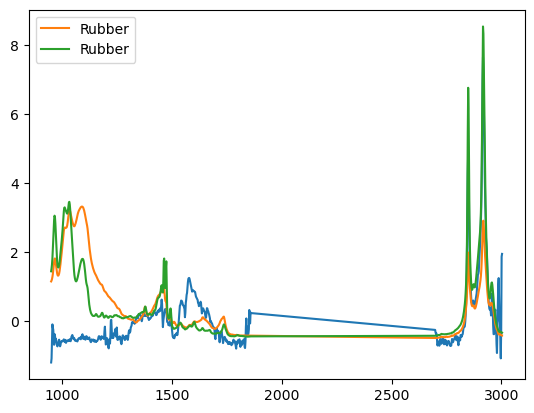

id           FHS_Run2_68
school               FHS
run                 Run2
sample_id             68
Name: 563, dtype: object


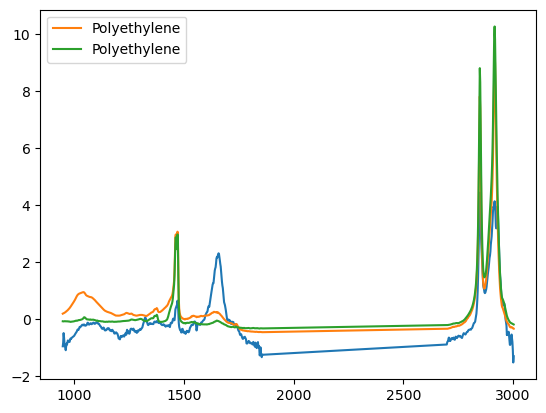

id           FHS_Run2_86
school               FHS
run                 Run2
sample_id             86
Name: 573, dtype: object


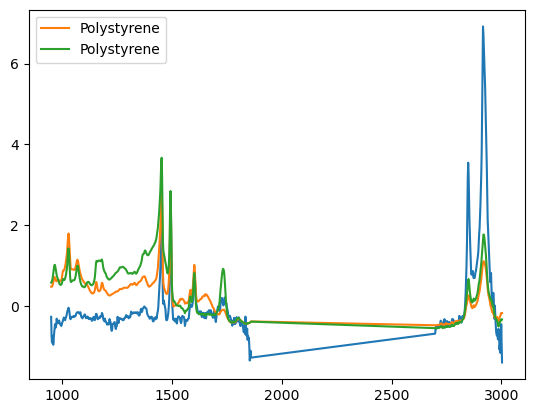

id           IAO_Run3_89
school               IAO
run                 Run3
sample_id             89
Name: 443, dtype: object


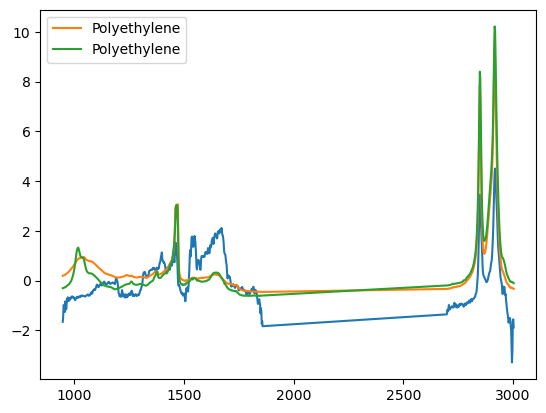

id           ICB_Run1_24
school               ICB
run                 Run1
sample_id             24
Name: 348, dtype: object


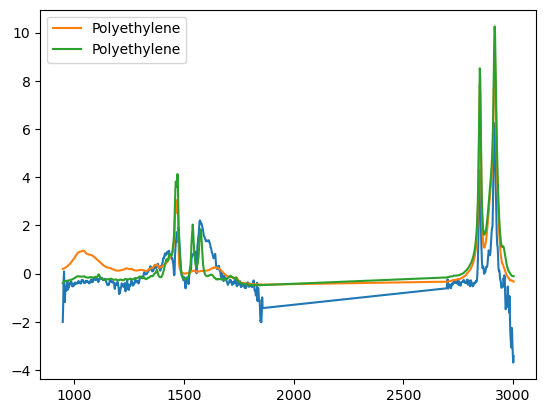

id           Daycroft_Run2_31
school               Daycroft
run                      Run2
sample_id                  31
Name: 175, dtype: object


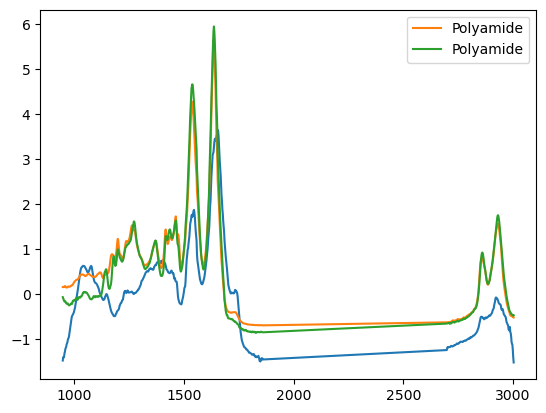

id           FHS_Run2_106
school                FHS
run                  Run2
sample_id             106
Name: 585, dtype: object


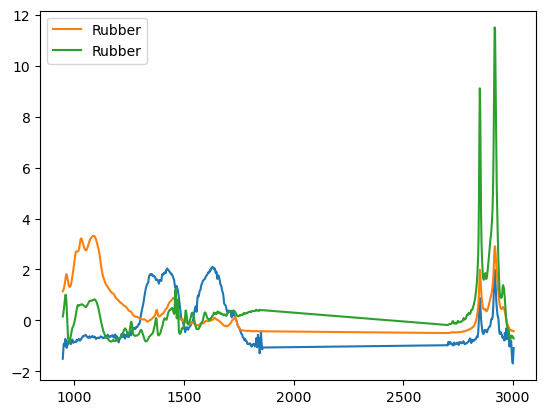

id           Daycroft_Run2_41
school               Daycroft
run                      Run2
sample_id                  41
Name: 183, dtype: object


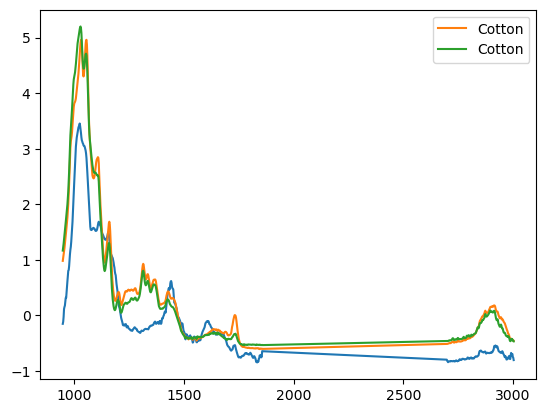

id           IAO_Run2_59
school               IAO
run                 Run2
sample_id             59
Name: 671, dtype: object


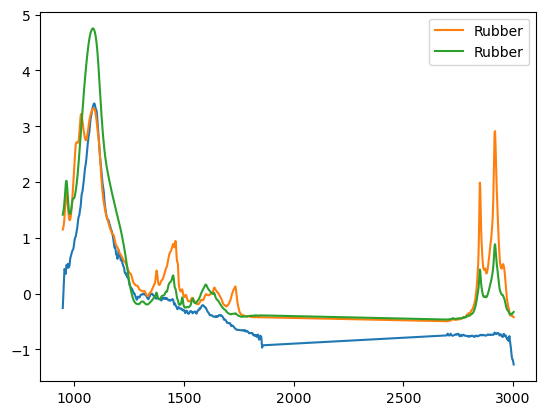

id           ICB_Run3_15
school               ICB
run                 Run3
sample_id             15
Name: 261, dtype: object


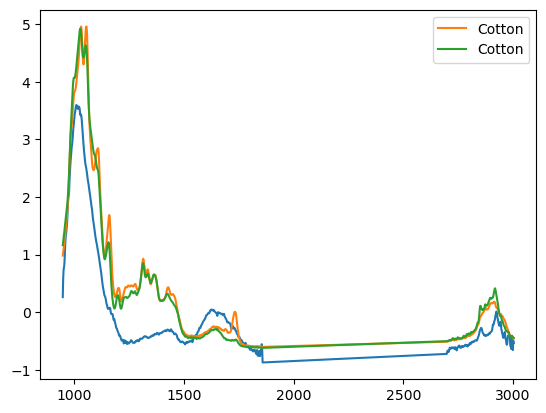

id           ICB_Run1_94
school               ICB
run                 Run1
sample_id             94
Name: 393, dtype: object


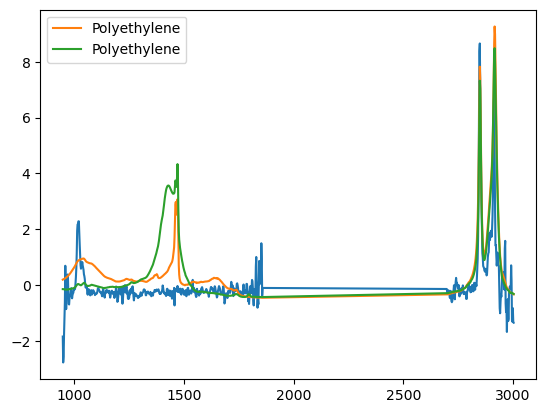

id           ICB_Run3_35
school               ICB
run                 Run3
sample_id             35
Name: 278, dtype: object


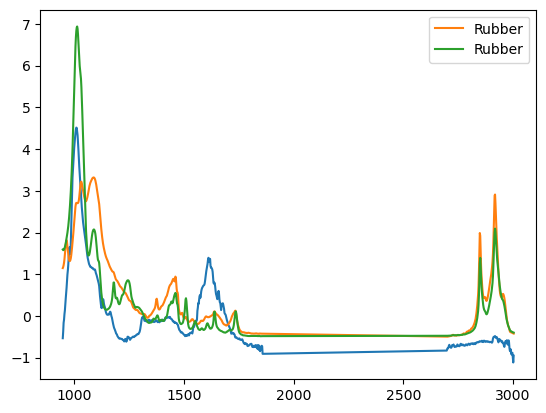

id           ICB_Run1_44
school               ICB
run                 Run1
sample_id             44
Name: 359, dtype: object


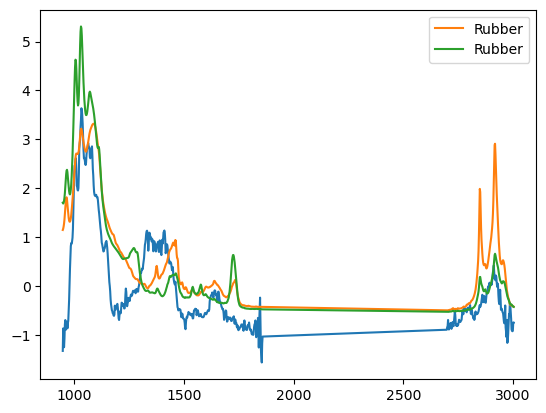

id           ICB_Run3_71
school               ICB
run                 Run3
sample_id             71
Name: 307, dtype: object


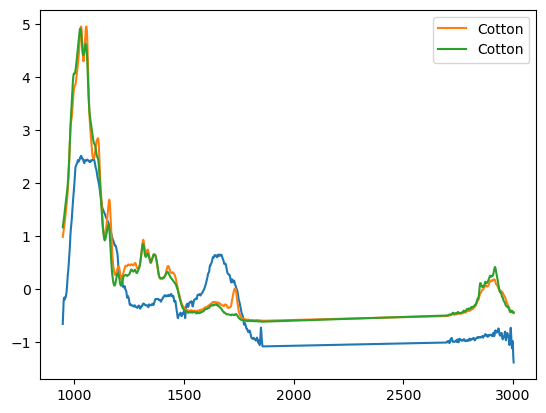

id           Daycroft_Run3_37
school               Daycroft
run                      Run3
sample_id                  37
Name: 24, dtype: object


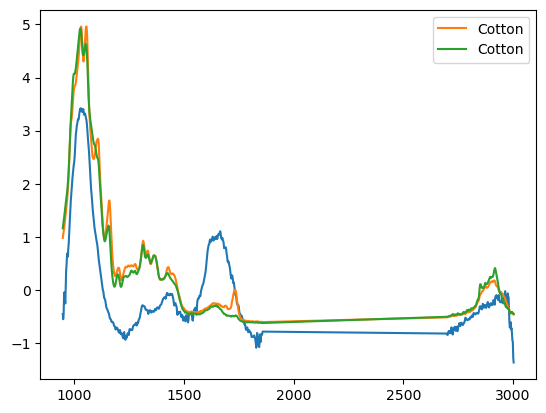

id           ICB_Run1_92
school               ICB
run                 Run1
sample_id             92
Name: 392, dtype: object


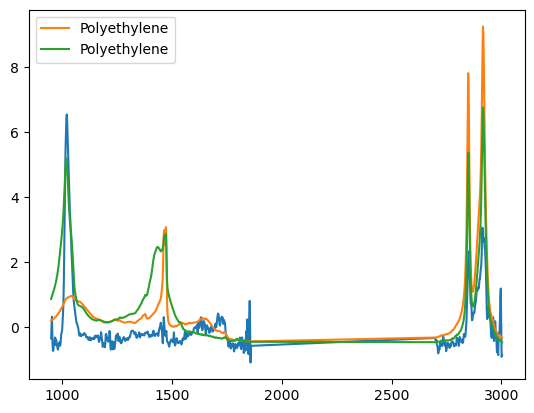

id           IAO_Run3_32
school               IAO
run                 Run3
sample_id             32
Name: 413, dtype: object


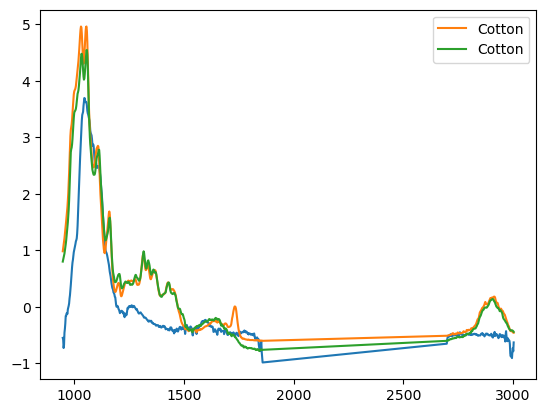

id           IAO_Run2_103
school                IAO
run                  Run2
sample_id             103
Name: 689, dtype: object


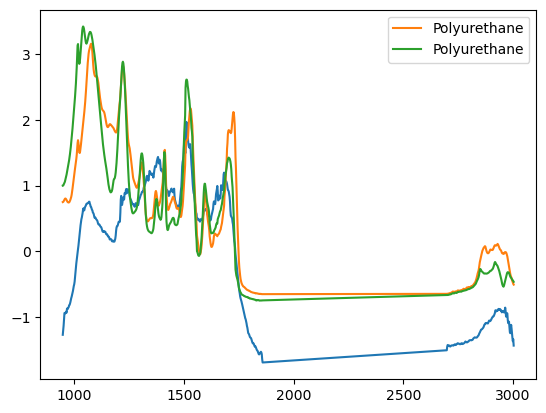

id           ICB_Run3_105
school                ICB
run                  Run3
sample_id             105
Name: 327, dtype: object


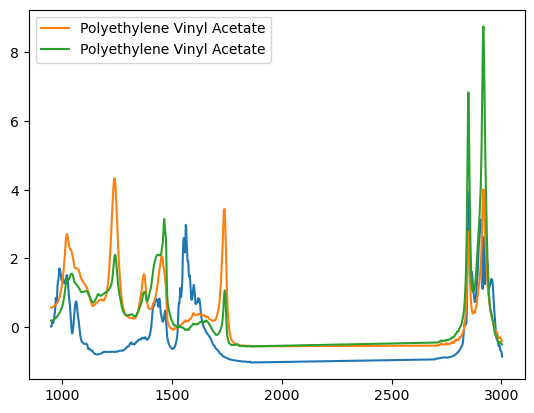

id           Daycroft_Run2_53
school               Daycroft
run                      Run2
sample_id                  53
Name: 193, dtype: object


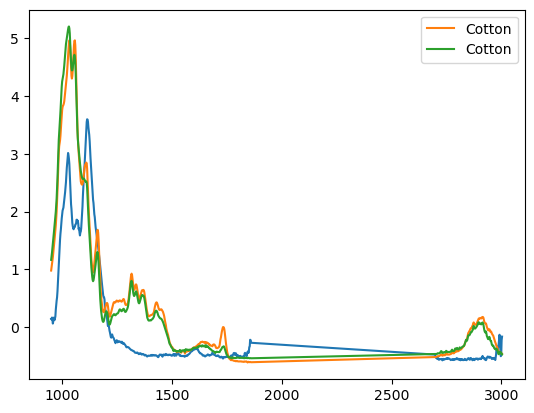

In [157]:
for i in np.argsort(distance_center_k_):
    if distance_center_k_[i]>27:
        break
    if std_2700_3000[i]<0.06:
        continue
    poly = pred_poly_diff[i] 
    poly_hqi = pred_polymers_hqi_diff[i] 
    
    if poly != poly_hqi:
        continue
        
    best_match = best_match_diff[i]
    print(spectra_data.iloc[i,-4:])
    plt.plot(wl_list_2[idx_range],spectra_data_np_norm[i,:])
    plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.query('polymer == @poly').iloc[:,4:].mean(0).loc[idx_range], label=poly)
    plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.iloc[best_match,4:].loc[idx_range], label=poly_hqi)
    plt.legend()
    plt.show()
    

In [158]:
spectra_data_int#.iloc[0,1]

wavelength,file_name,674.9918,676.9203482598608,678.8488965197216,680.7774447795824,682.7059930394431,684.6345412993039,686.5630895591647,688.4916378190255,690.4201860788863,...,3982.452065661253,3984.3806139211138,3986.3091621809745,3988.237710440835,3990.1662587006967,3992.0948069605574,3994.023355220418,3995.951903480279,3997.8804517401395,3999.809
0,Daycroft_Run1_10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Daycroft_Run1_101,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Daycroft_Run1_103,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Daycroft_Run1_13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Daycroft_Run1_15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
687,ICB_Run3_91,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
688,ICB_Run3_92,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
689,ICB_Run3_96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
690,ICB_Run3_98,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


id           IAO_Run1_88
school               IAO
run                 Run1
sample_id             88
Name: 94, dtype: object


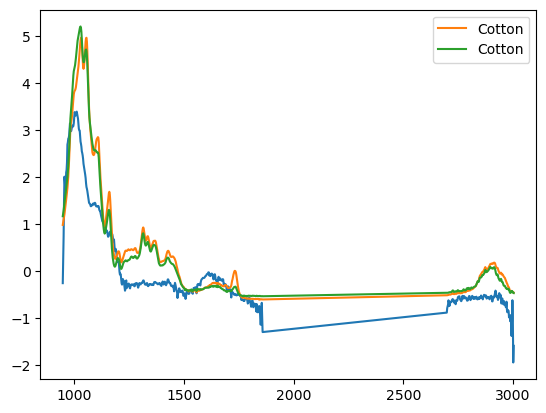

id           IAO_Run1_91
school               IAO
run                 Run1
sample_id             91
Name: 95, dtype: object


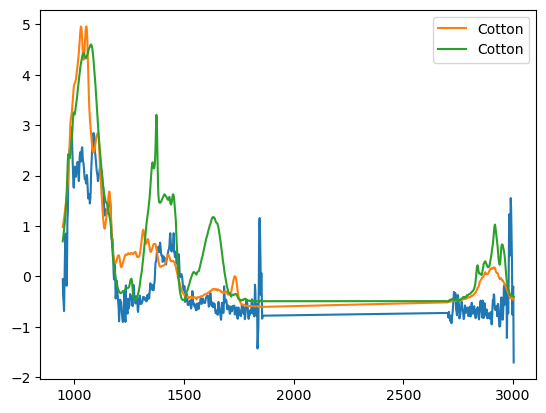

id           IAO_Run1_92
school               IAO
run                 Run1
sample_id             92
Name: 96, dtype: object


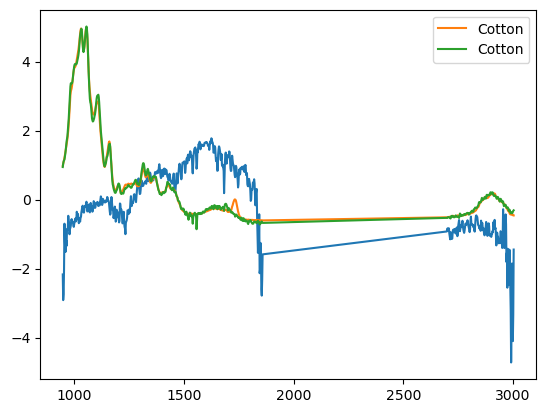

id           IAO_Run1_93
school               IAO
run                 Run1
sample_id             93
Name: 97, dtype: object


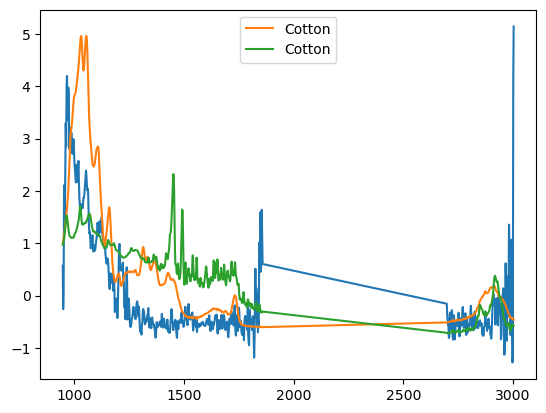

id           IAO_Run1_96
school               IAO
run                 Run1
sample_id             96
Name: 98, dtype: object


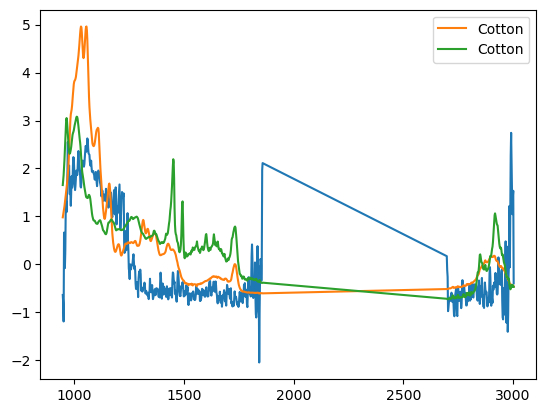

id           IAO_Run1_97
school               IAO
run                 Run1
sample_id             97
Name: 99, dtype: object


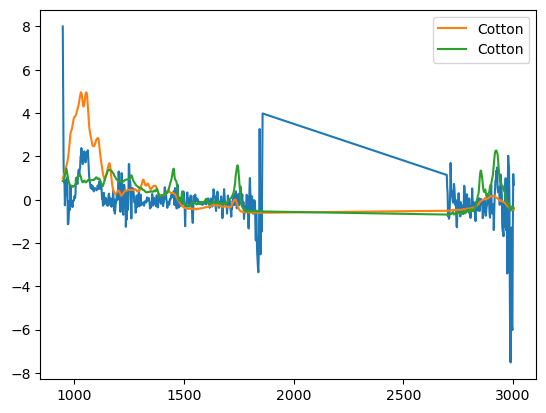

id           IAO_Run1_98
school               IAO
run                 Run1
sample_id             98
Name: 100, dtype: object


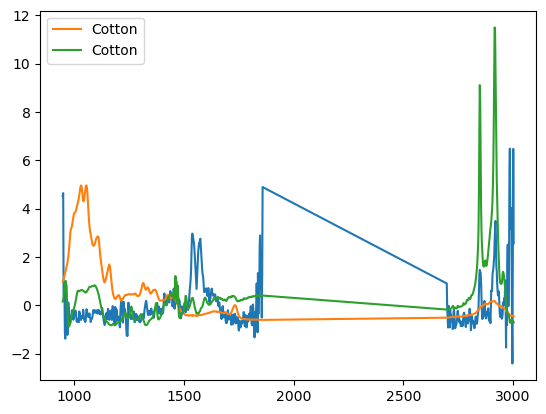

id           IAO_Run1_101
school                IAO
run                  Run1
sample_id             101
Name: 101, dtype: object


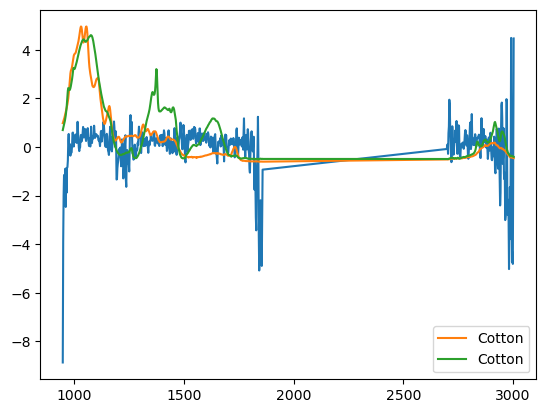

id           IAO_Run1_102
school                IAO
run                  Run1
sample_id             102
Name: 102, dtype: object


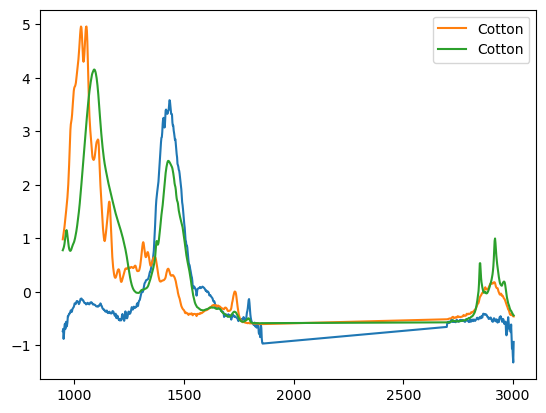

id           IAO_Run1_103
school                IAO
run                  Run1
sample_id             103
Name: 103, dtype: object


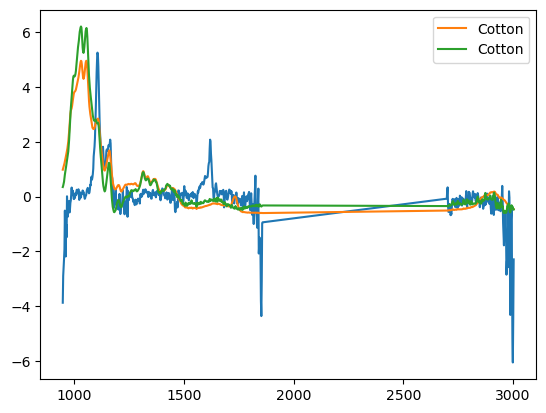

id           IAO_Run1_104
school                IAO
run                  Run1
sample_id             104
Name: 104, dtype: object


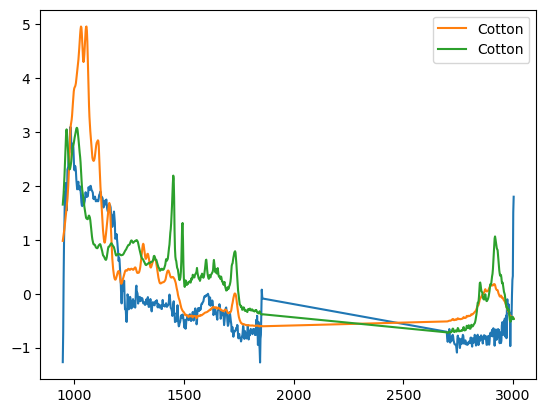

id           FHS_Run1_1
school              FHS
run                Run1
sample_id             1
Name: 105, dtype: object


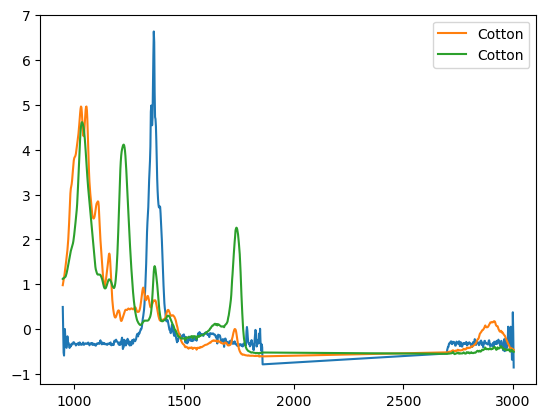

id           FHS_Run1_2
school              FHS
run                Run1
sample_id             2
Name: 106, dtype: object


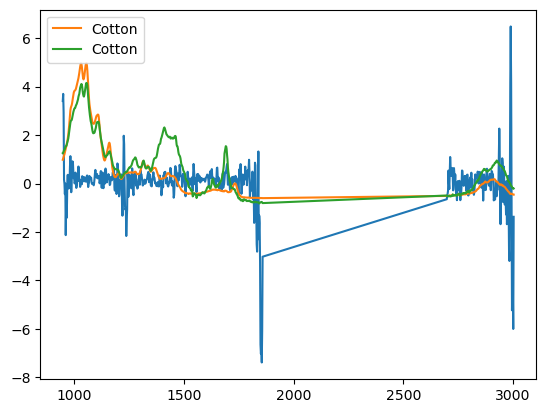

id           FHS_Run1_3
school              FHS
run                Run1
sample_id             3
Name: 107, dtype: object


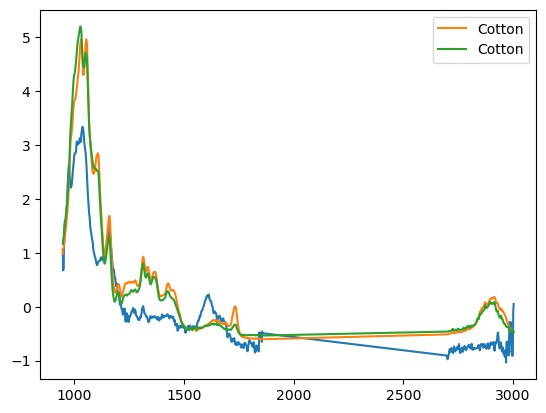

id           FHS_Run1_7
school              FHS
run                Run1
sample_id             7
Name: 108, dtype: object


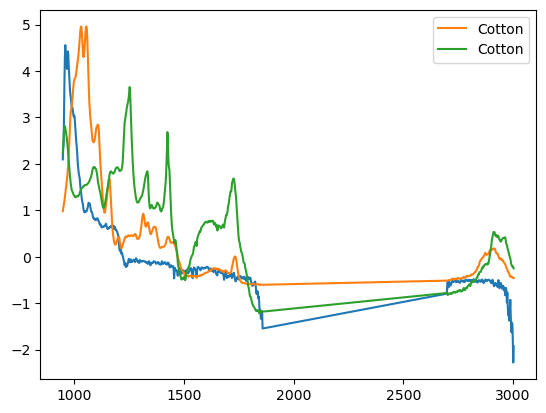

id           FHS_Run1_8
school              FHS
run                Run1
sample_id             8
Name: 109, dtype: object


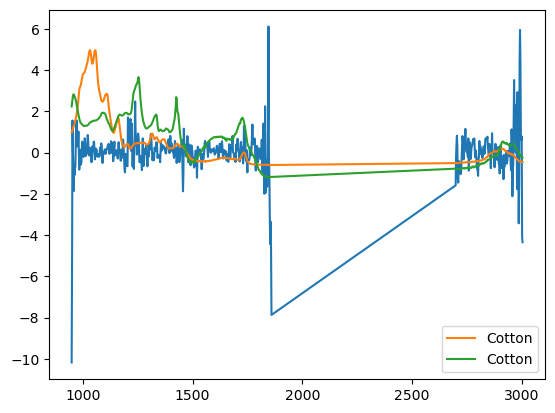

id           FHS_Run1_9
school              FHS
run                Run1
sample_id             9
Name: 110, dtype: object


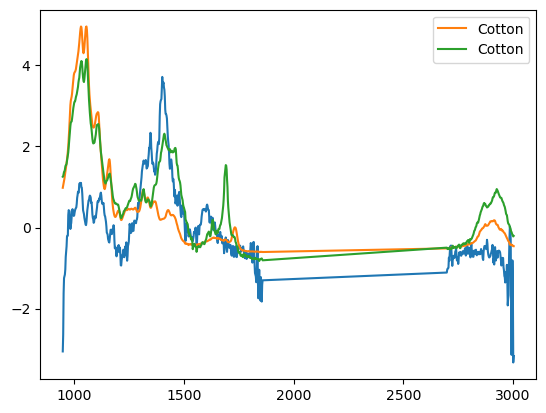

id           FHS_Run1_13
school               FHS
run                 Run1
sample_id             13
Name: 111, dtype: object


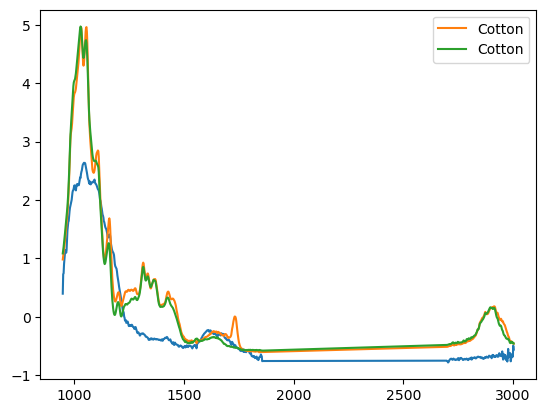

id           FHS_Run1_14
school               FHS
run                 Run1
sample_id             14
Name: 112, dtype: object


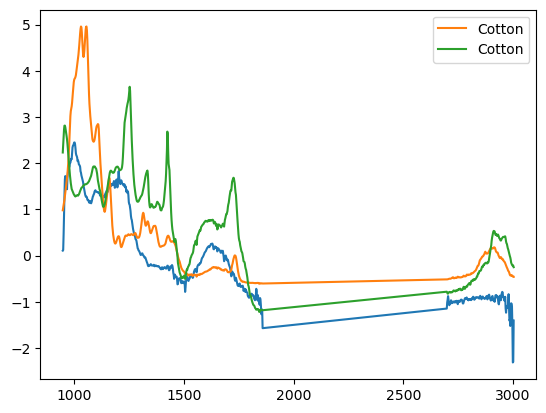

id           FHS_Run1_15
school               FHS
run                 Run1
sample_id             15
Name: 113, dtype: object


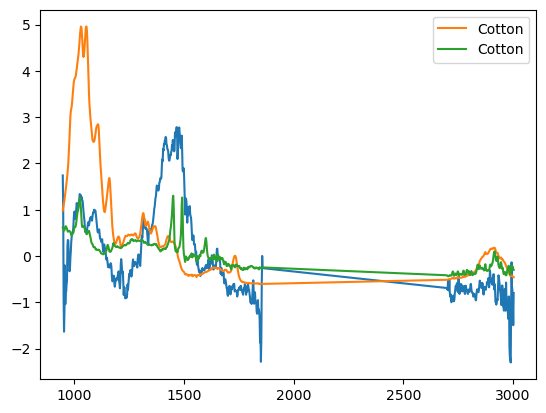

id           FHS_Run1_20
school               FHS
run                 Run1
sample_id             20
Name: 114, dtype: object


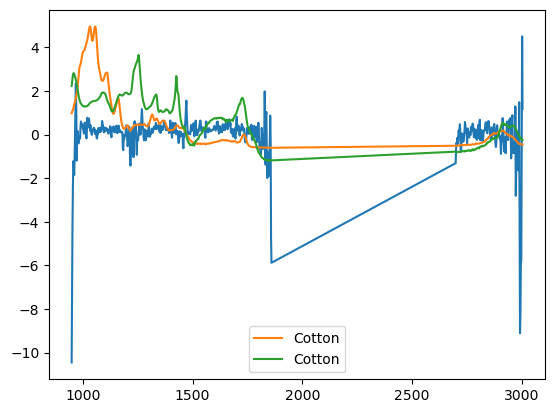

id           FHS_Run1_22
school               FHS
run                 Run1
sample_id             22
Name: 115, dtype: object


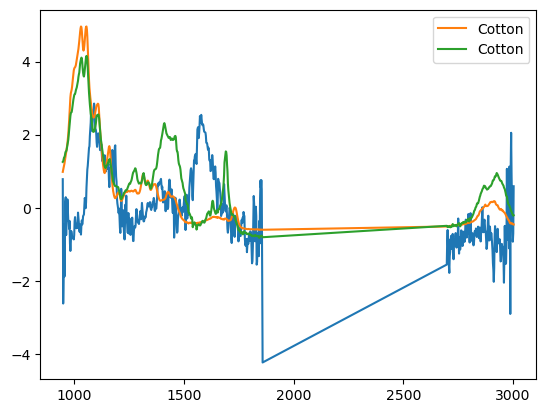

id           FHS_Run1_23
school               FHS
run                 Run1
sample_id             23
Name: 116, dtype: object


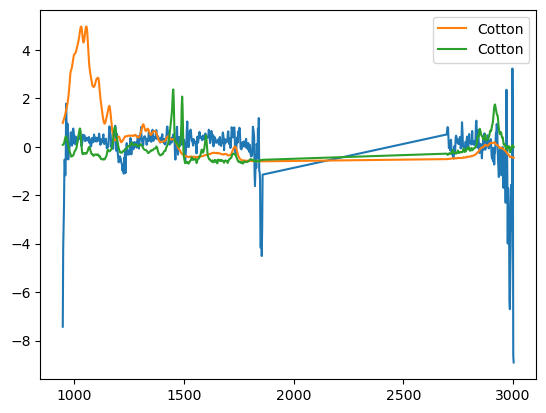

id           FHS_Run1_26
school               FHS
run                 Run1
sample_id             26
Name: 117, dtype: object


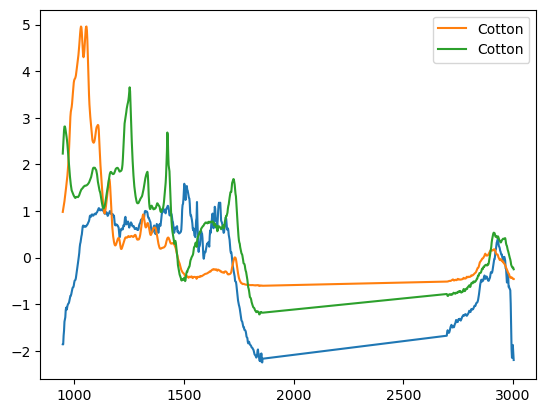

id           FHS_Run1_27
school               FHS
run                 Run1
sample_id             27
Name: 118, dtype: object


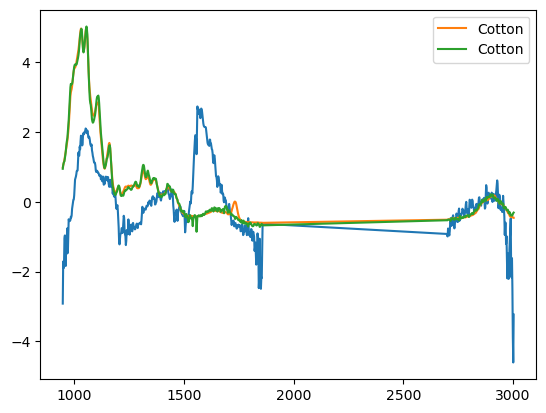

id           FHS_Run1_28
school               FHS
run                 Run1
sample_id             28
Name: 119, dtype: object


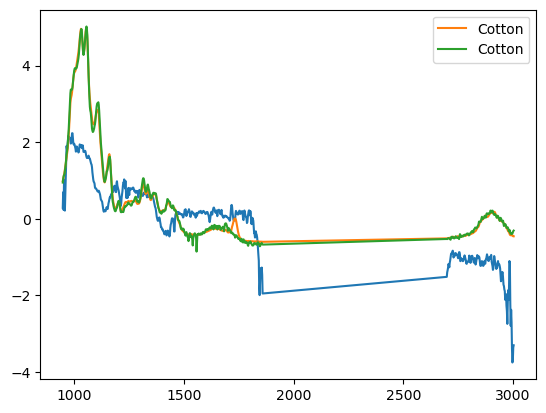

id           FHS_Run1_29
school               FHS
run                 Run1
sample_id             29
Name: 120, dtype: object


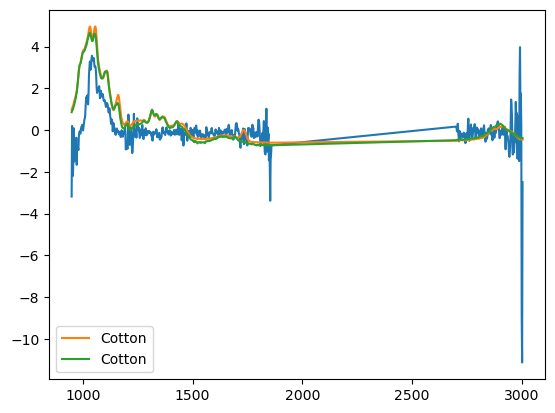

id           FHS_Run1_30
school               FHS
run                 Run1
sample_id             30
Name: 121, dtype: object


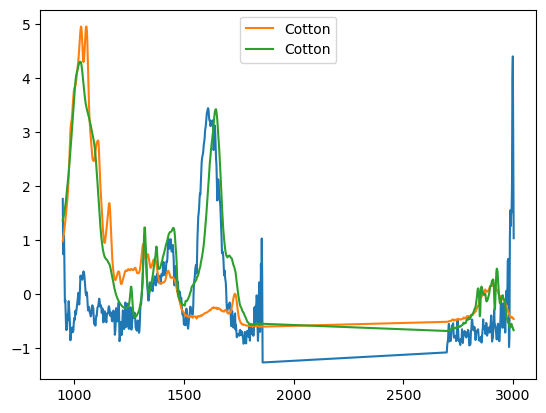

id           FHS_Run1_31
school               FHS
run                 Run1
sample_id             31
Name: 122, dtype: object


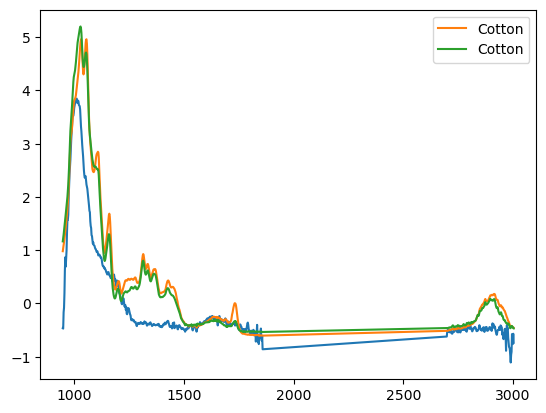

id           FHS_Run1_34
school               FHS
run                 Run1
sample_id             34
Name: 123, dtype: object


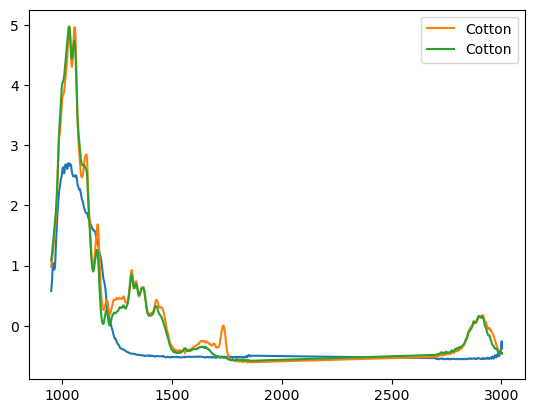

id           FHS_Run1_35
school               FHS
run                 Run1
sample_id             35
Name: 124, dtype: object


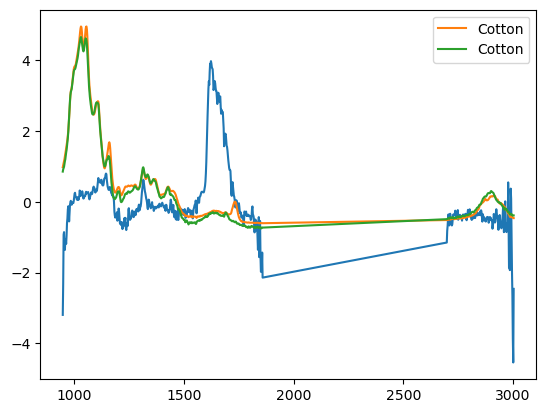

id           FHS_Run1_36
school               FHS
run                 Run1
sample_id             36
Name: 125, dtype: object


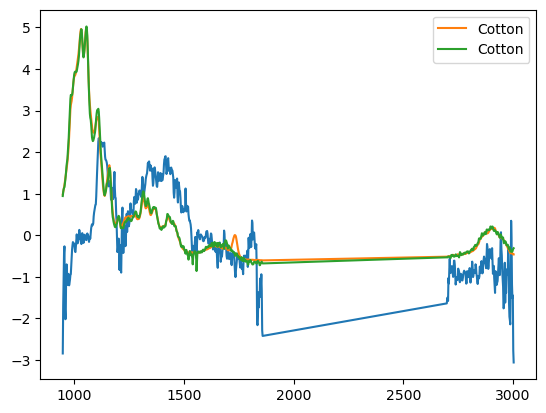

id           FHS_Run1_40
school               FHS
run                 Run1
sample_id             40
Name: 126, dtype: object


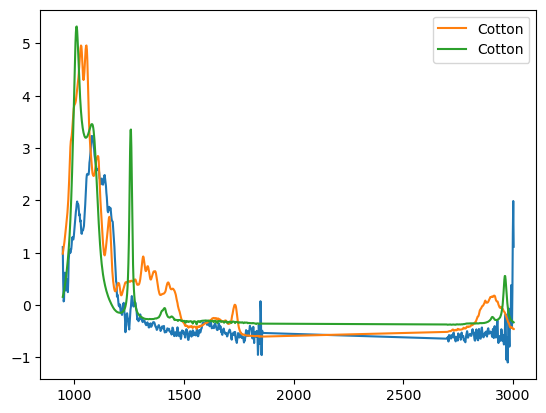

id           FHS_Run1_44
school               FHS
run                 Run1
sample_id             44
Name: 127, dtype: object


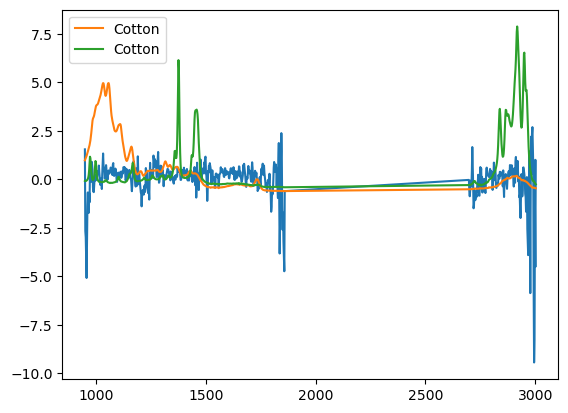

id           FHS_Run1_45
school               FHS
run                 Run1
sample_id             45
Name: 128, dtype: object


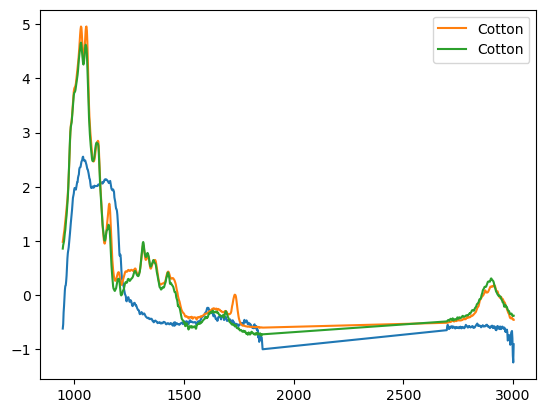

id           FHS_Run1_46
school               FHS
run                 Run1
sample_id             46
Name: 129, dtype: object


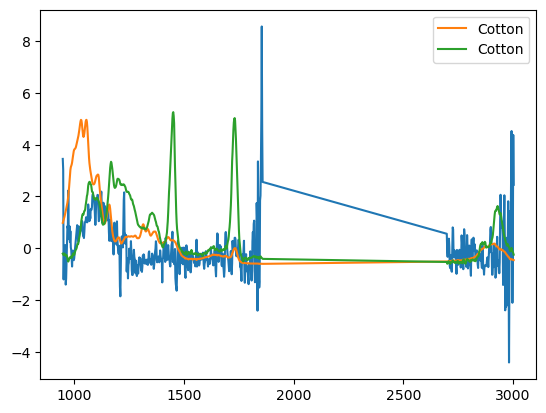

id           FHS_Run1_48
school               FHS
run                 Run1
sample_id             48
Name: 130, dtype: object


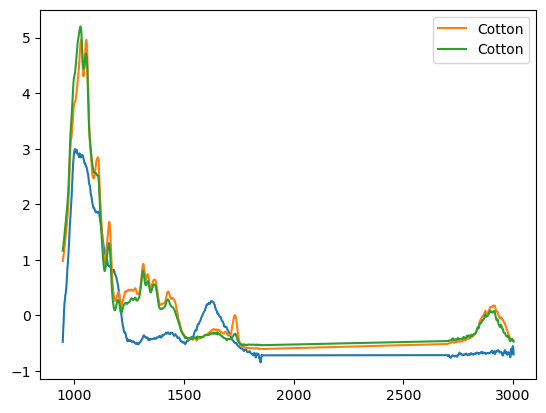

id           FHS_Run1_49
school               FHS
run                 Run1
sample_id             49
Name: 131, dtype: object


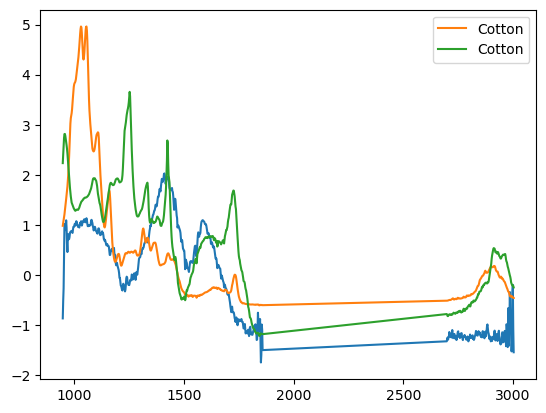

id           FHS_Run1_50
school               FHS
run                 Run1
sample_id             50
Name: 132, dtype: object


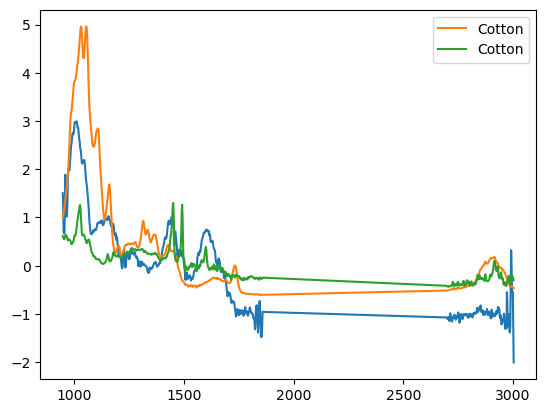

id           FHS_Run1_51
school               FHS
run                 Run1
sample_id             51
Name: 133, dtype: object


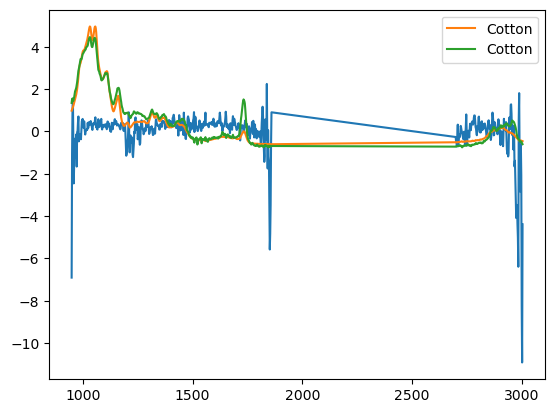

id           FHS_Run1_52
school               FHS
run                 Run1
sample_id             52
Name: 134, dtype: object


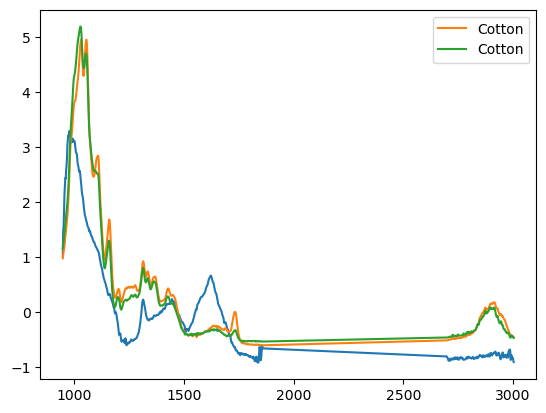

id           FHS_Run1_53
school               FHS
run                 Run1
sample_id             53
Name: 135, dtype: object


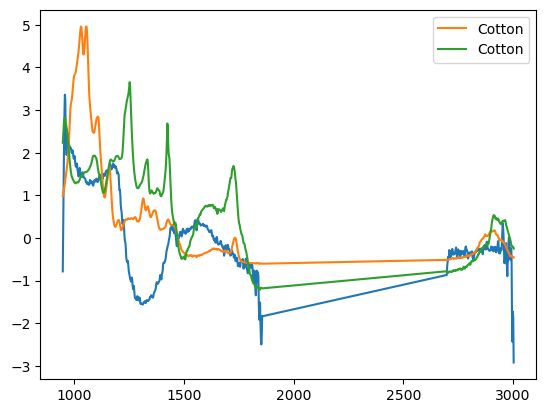

id           FHS_Run1_54
school               FHS
run                 Run1
sample_id             54
Name: 136, dtype: object


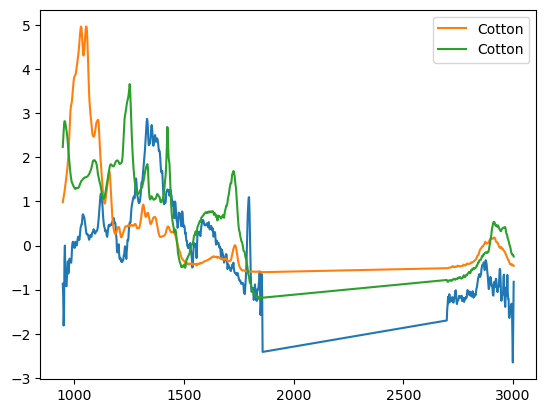

id           FHS_Run1_55
school               FHS
run                 Run1
sample_id             55
Name: 137, dtype: object


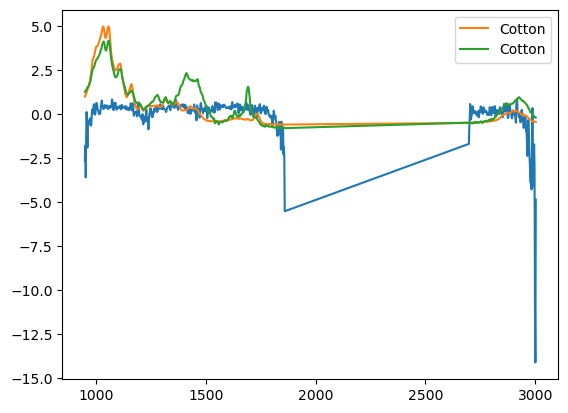

id           FHS_Run1_56
school               FHS
run                 Run1
sample_id             56
Name: 138, dtype: object


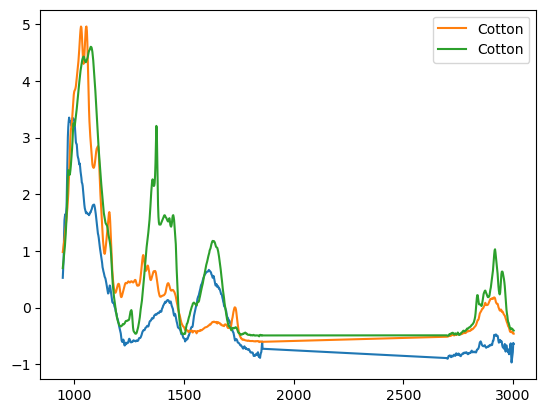

id           FHS_Run1_57
school               FHS
run                 Run1
sample_id             57
Name: 139, dtype: object


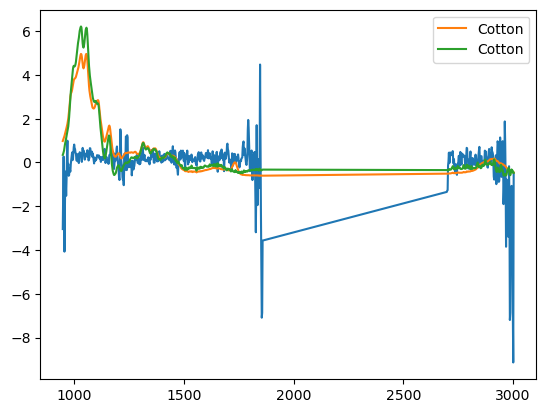

id           FHS_Run1_58
school               FHS
run                 Run1
sample_id             58
Name: 140, dtype: object


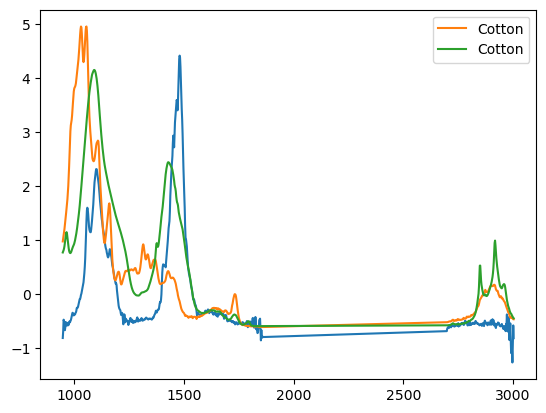

id           FHS_Run1_59
school               FHS
run                 Run1
sample_id             59
Name: 141, dtype: object


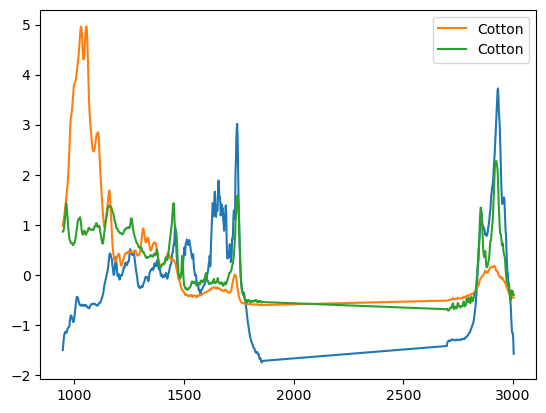

id           FHS_Run1_60
school               FHS
run                 Run1
sample_id             60
Name: 142, dtype: object


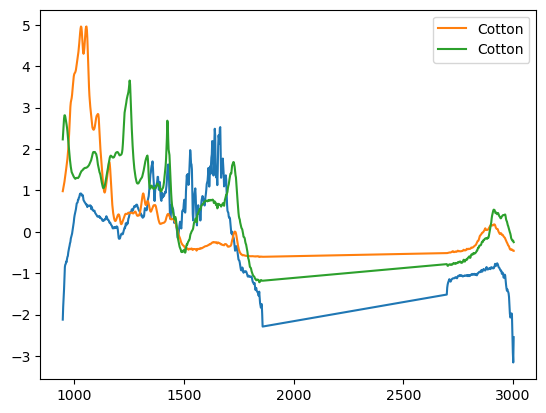

id           FHS_Run1_62
school               FHS
run                 Run1
sample_id             62
Name: 143, dtype: object


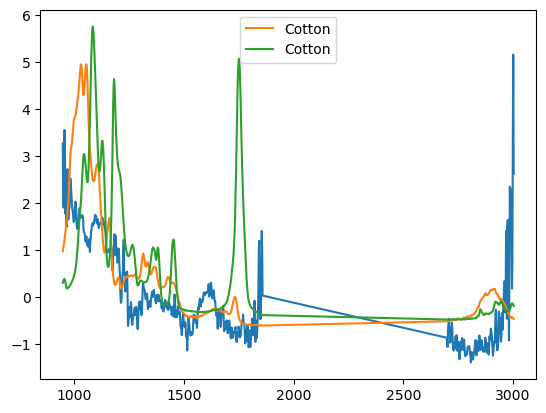

id           FHS_Run1_65
school               FHS
run                 Run1
sample_id             65
Name: 144, dtype: object


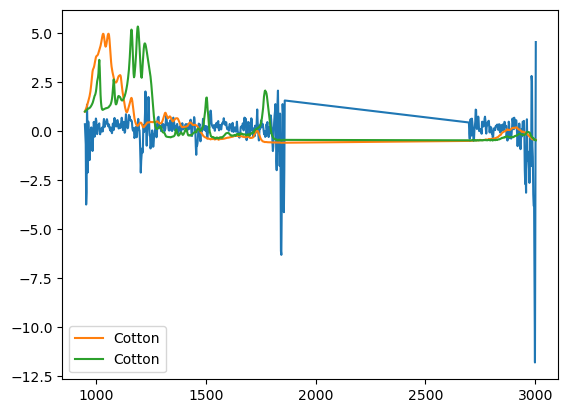

id           FHS_Run1_66
school               FHS
run                 Run1
sample_id             66
Name: 145, dtype: object


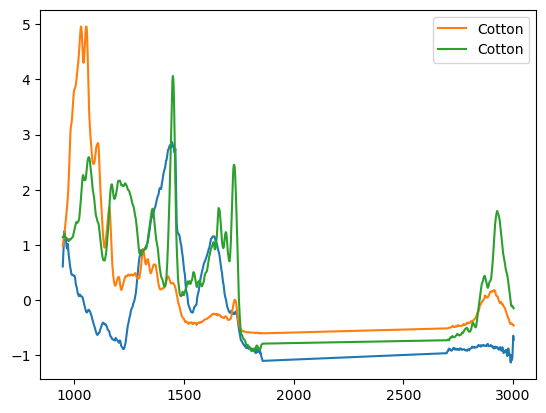

id           FHS_Run1_69
school               FHS
run                 Run1
sample_id             69
Name: 146, dtype: object


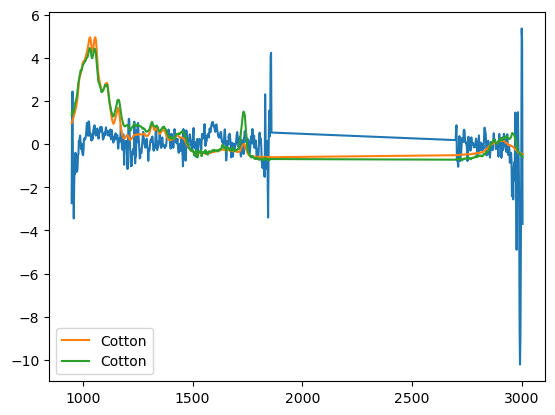

id           FHS_Run1_70
school               FHS
run                 Run1
sample_id             70
Name: 147, dtype: object


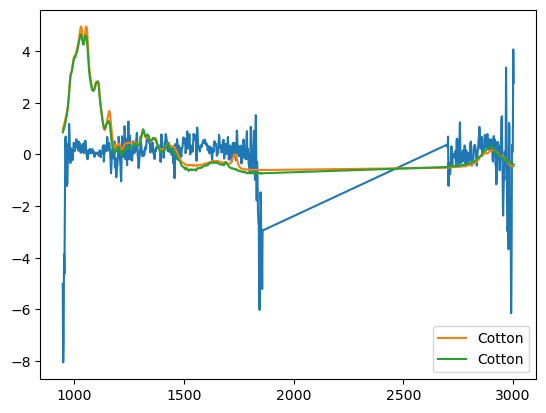

id           FHS_Run1_71
school               FHS
run                 Run1
sample_id             71
Name: 148, dtype: object


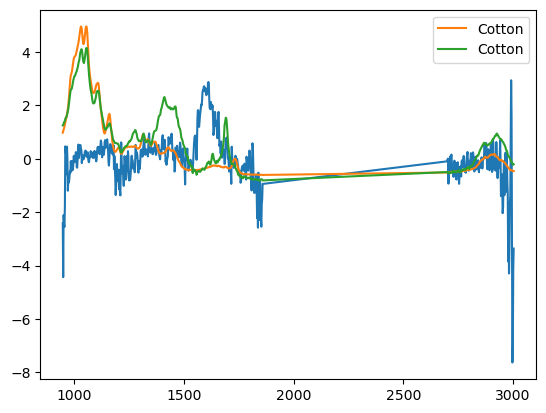

id           FHS_Run1_74
school               FHS
run                 Run1
sample_id             74
Name: 149, dtype: object


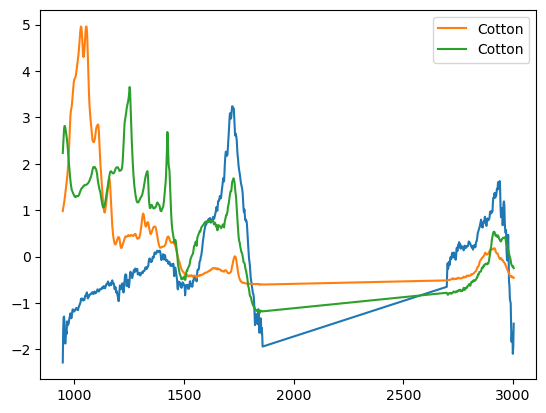

id           FHS_Run1_75
school               FHS
run                 Run1
sample_id             75
Name: 150, dtype: object


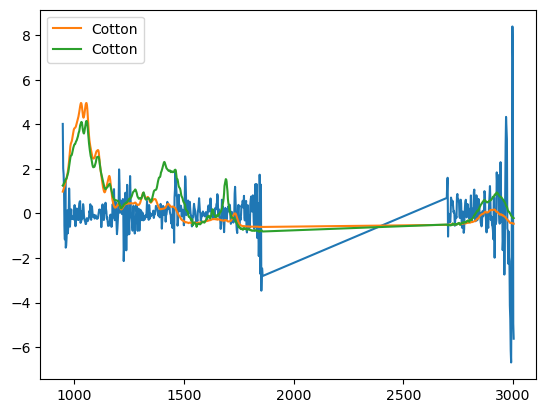

id           FHS_Run1_76
school               FHS
run                 Run1
sample_id             76
Name: 151, dtype: object


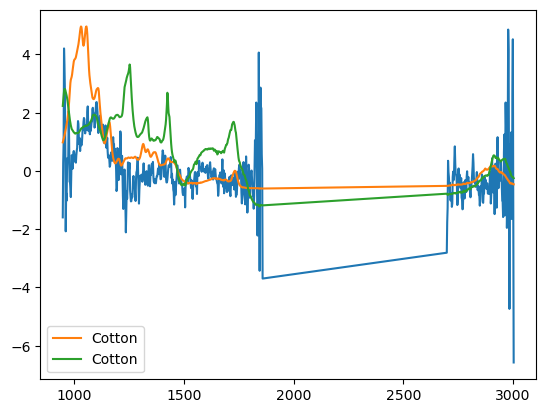

id           FHS_Run1_77
school               FHS
run                 Run1
sample_id             77
Name: 152, dtype: object


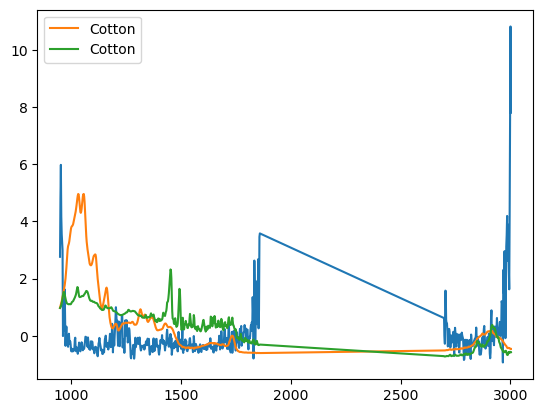

id           FHS_Run1_80
school               FHS
run                 Run1
sample_id             80
Name: 153, dtype: object


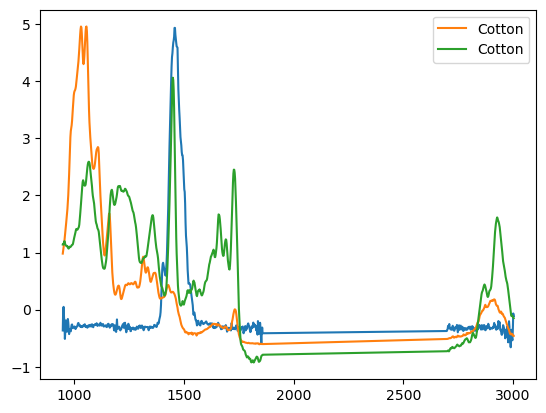

id           FHS_Run1_84
school               FHS
run                 Run1
sample_id             84
Name: 154, dtype: object


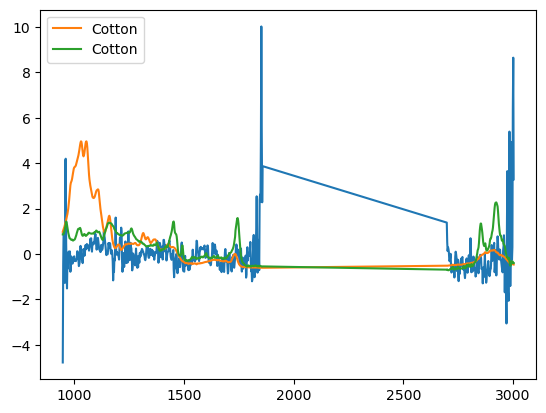

id           FHS_Run1_85
school               FHS
run                 Run1
sample_id             85
Name: 155, dtype: object


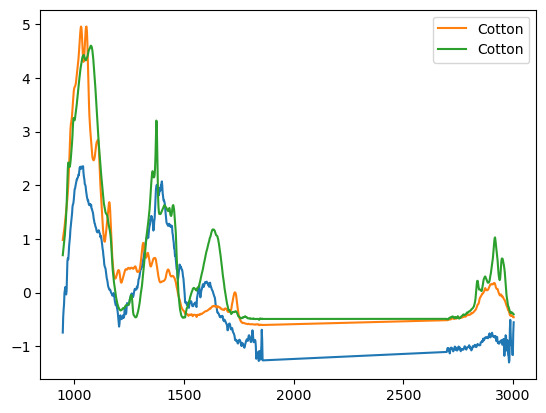

id           FHS_Run1_88
school               FHS
run                 Run1
sample_id             88
Name: 156, dtype: object


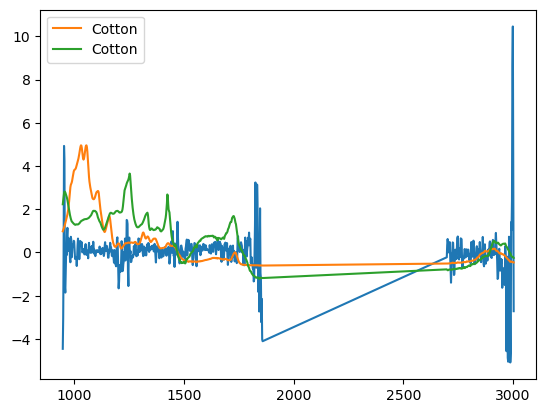

id           FHS_Run1_90
school               FHS
run                 Run1
sample_id             90
Name: 157, dtype: object


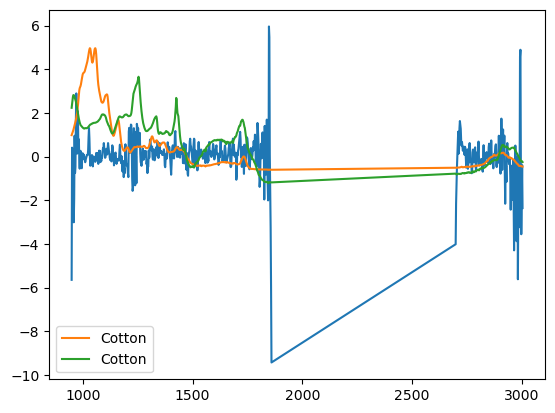

id           FHS_Run1_94
school               FHS
run                 Run1
sample_id             94
Name: 158, dtype: object


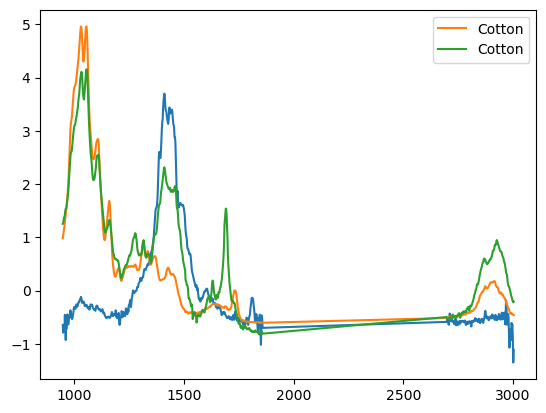

id           FHS_Run1_95
school               FHS
run                 Run1
sample_id             95
Name: 159, dtype: object


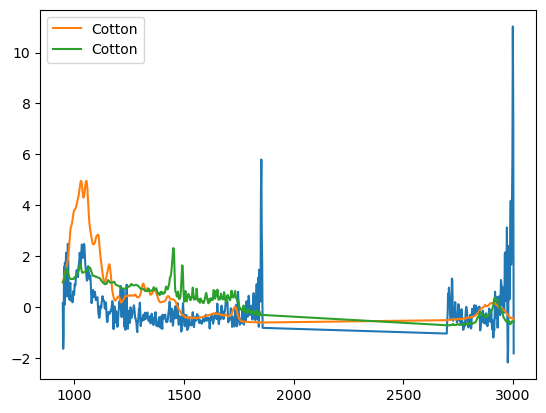

id           FHS_Run1_96
school               FHS
run                 Run1
sample_id             96
Name: 160, dtype: object


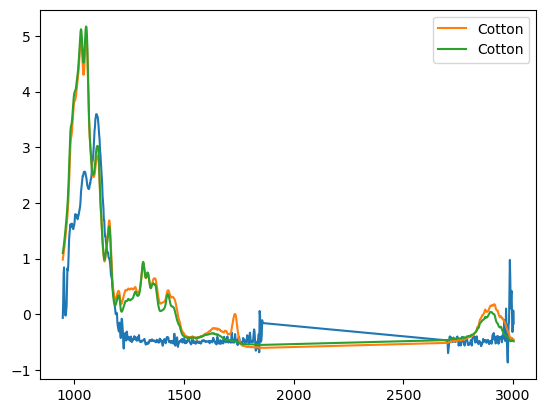

IndexError: index 692 is out of bounds for axis 0 with size 692

In [179]:
for i in range(692):
    #if distance_center_k_[i]>27:
    #    break
    
    if spectra_data_int.iloc[i,0] not in np.array(spectra_data.query('school == "Daycroft" and (run == "Run3")')['id']):
        continue
    
    best_match = best_match_diff[i]
    print(spectra_data.iloc[i,-4:])
    plt.plot(wl_list_2[idx_range],spectra_data_np_norm[i,:])
    plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.query('polymer == @poly').iloc[:,4:].mean(0).loc[idx_range], label=poly)
    plt.plot(wl_list_2[idx_range], -flopp_flopp_e_pivot.iloc[best_match,4:].loc[idx_range], label=poly_hqi)
    plt.legend()
    plt.show()
    

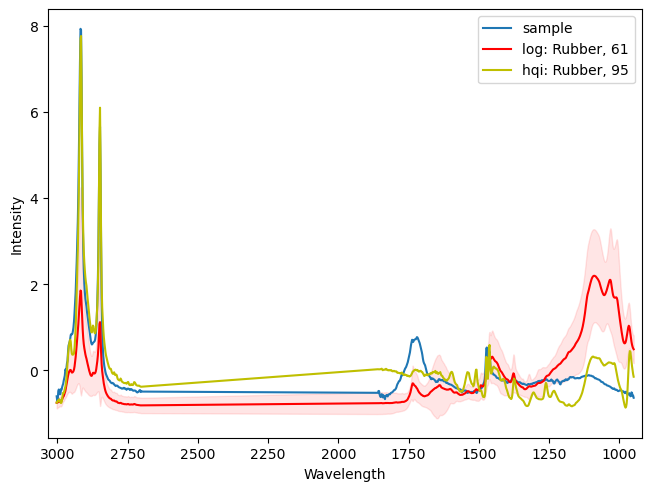

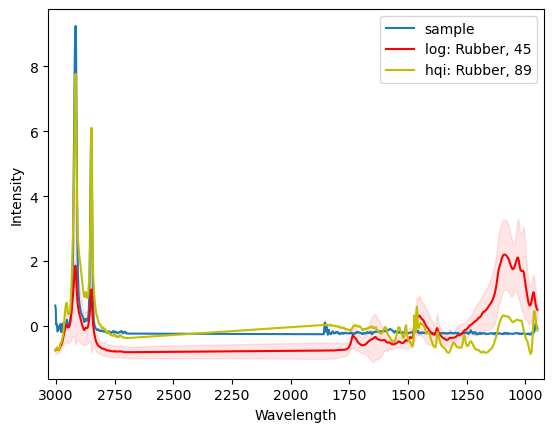

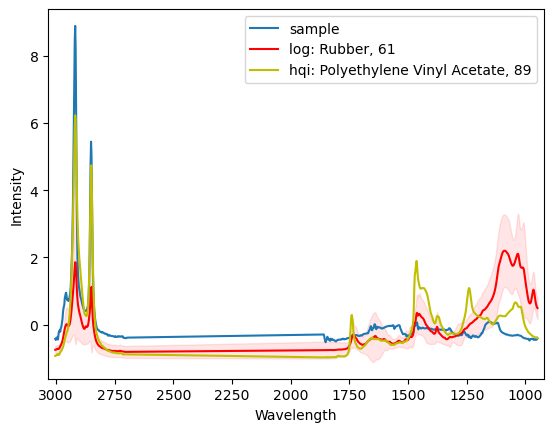

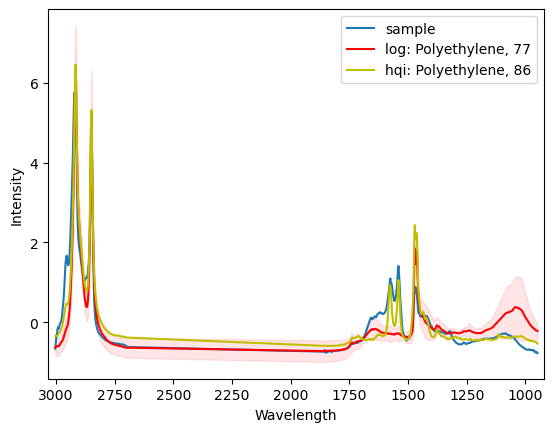

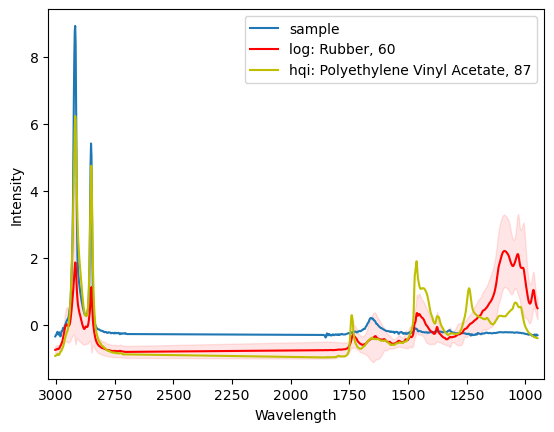

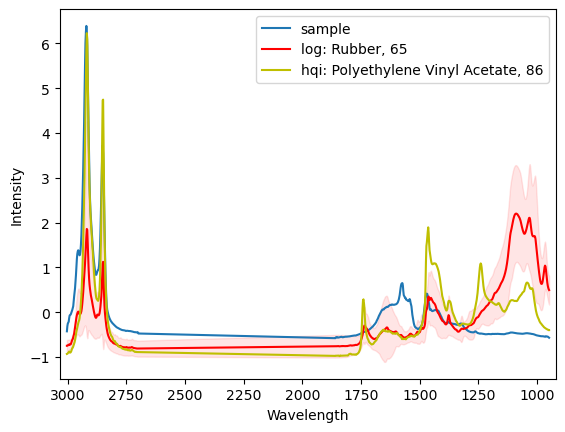

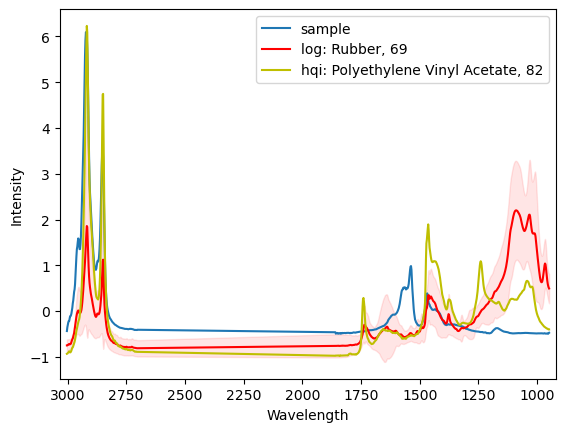

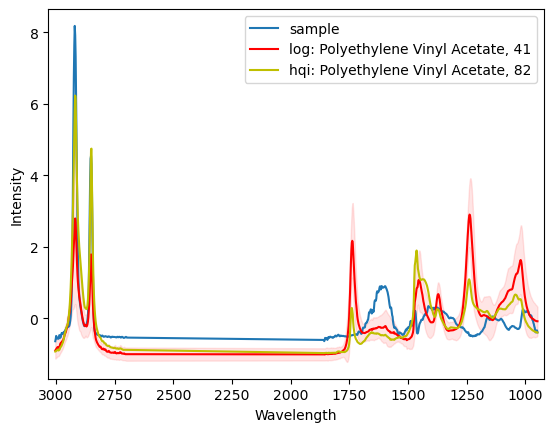

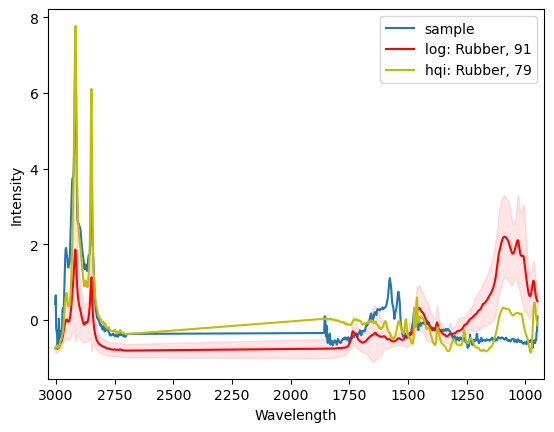

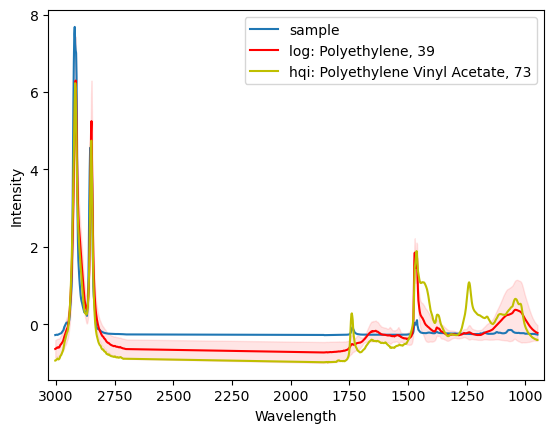

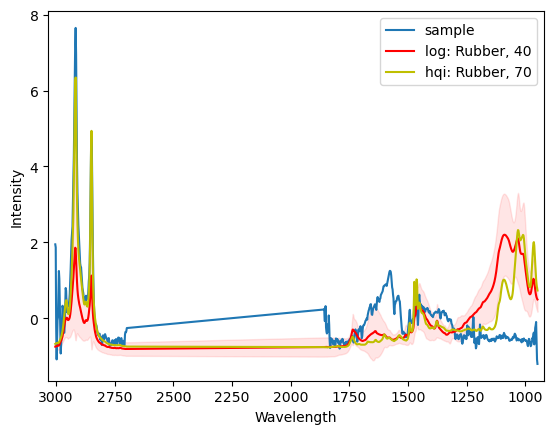

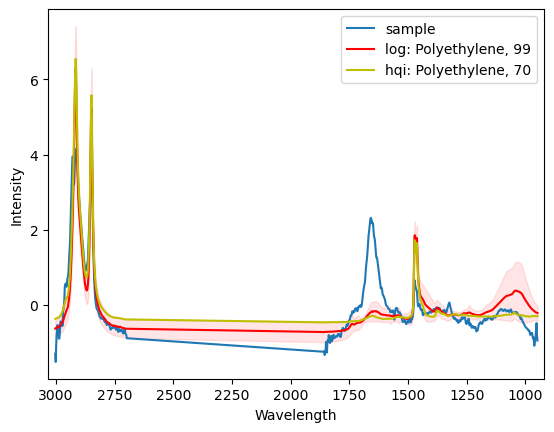

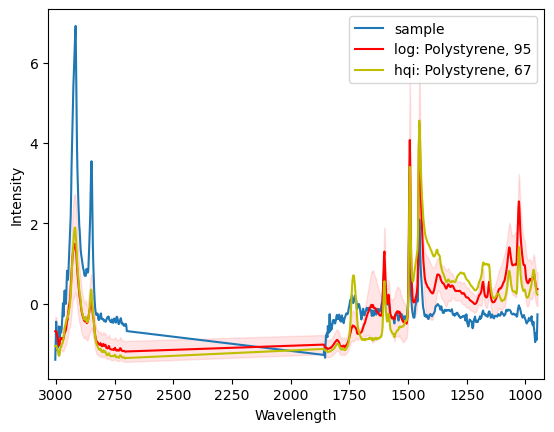

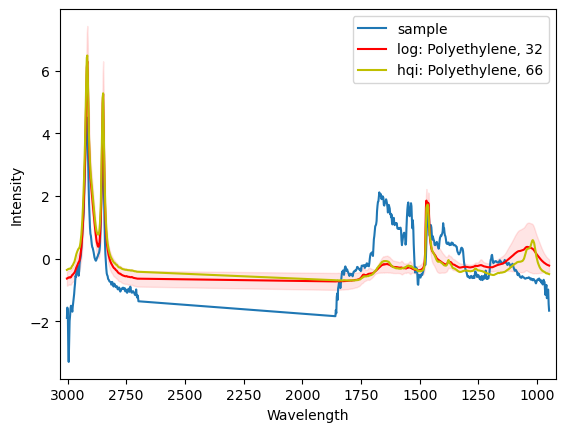

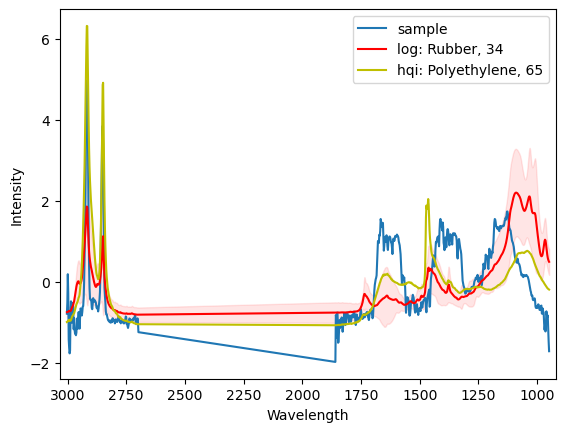

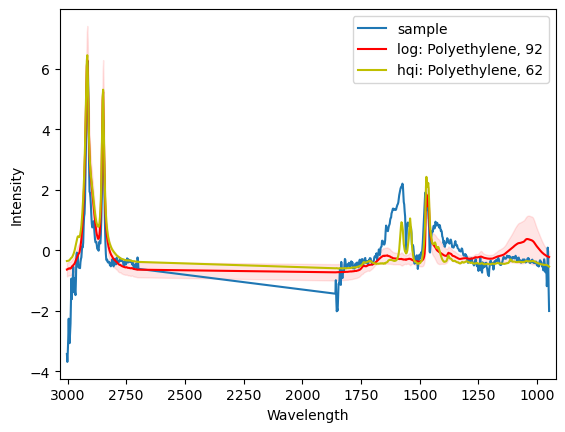

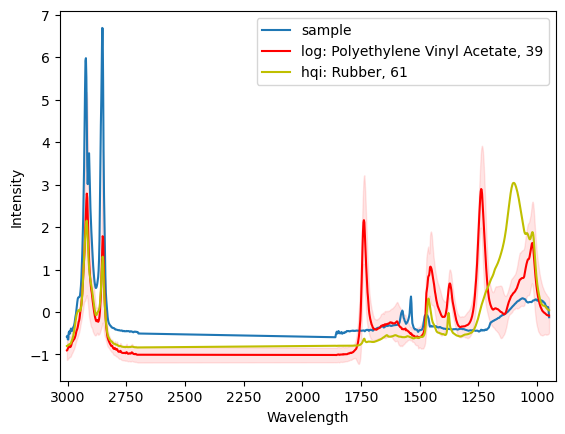

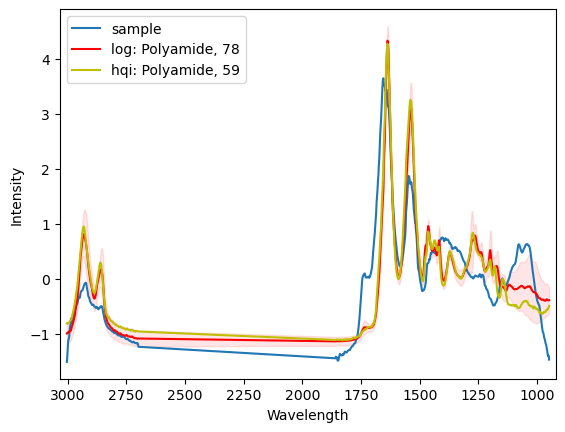

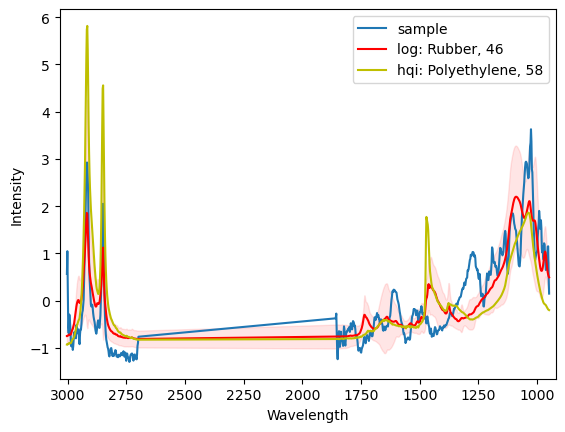

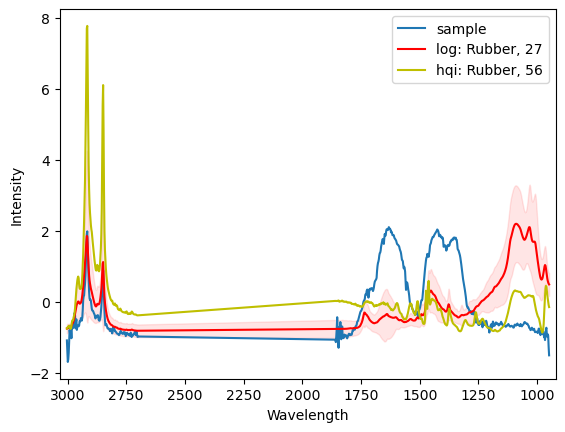

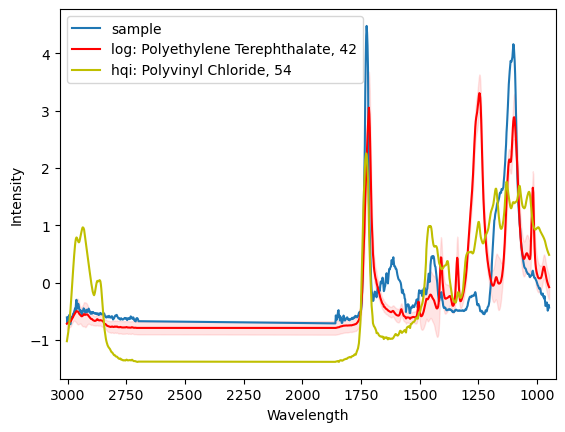

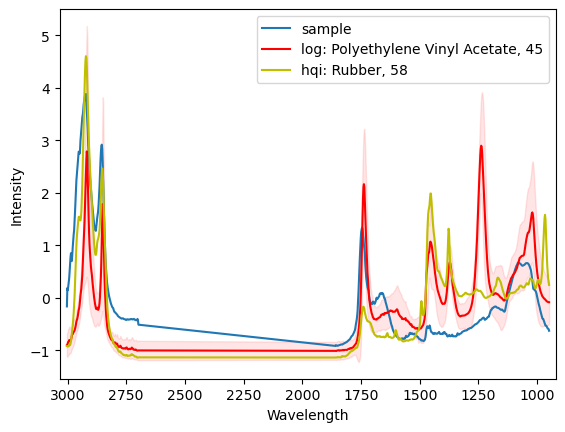

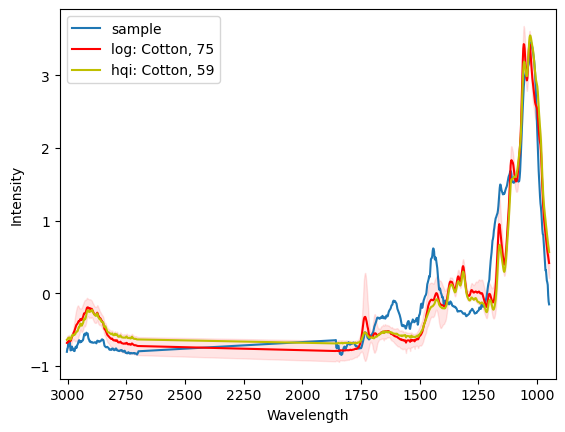

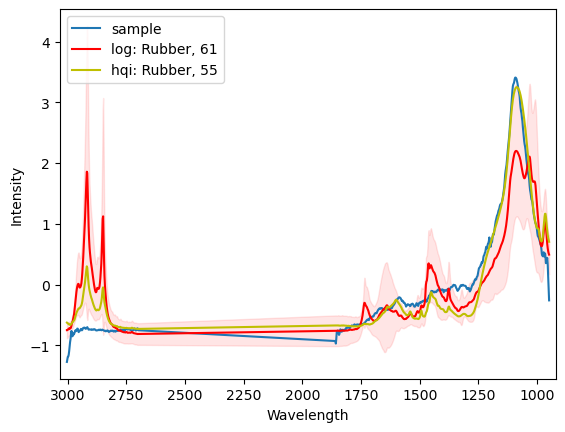

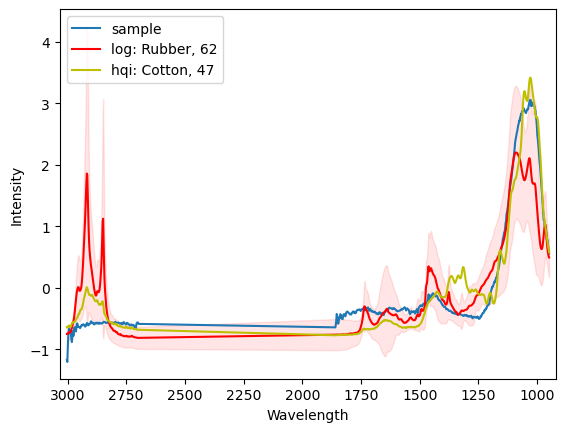

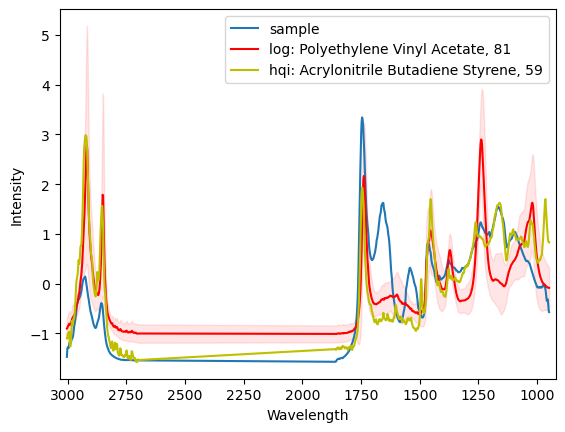

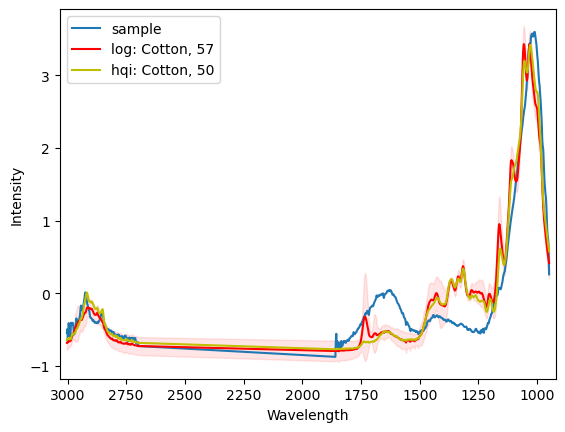

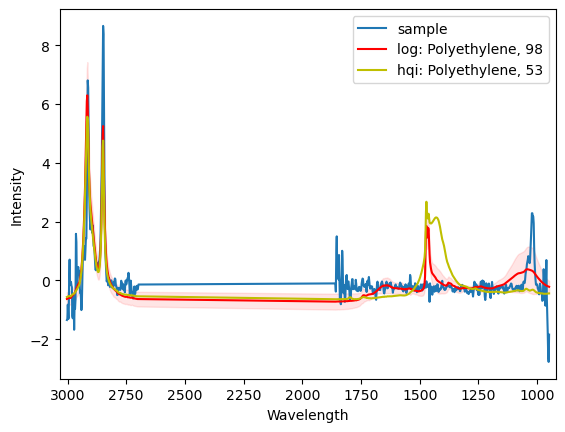

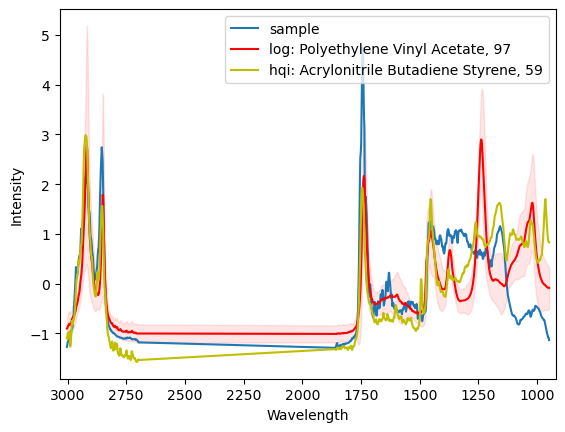

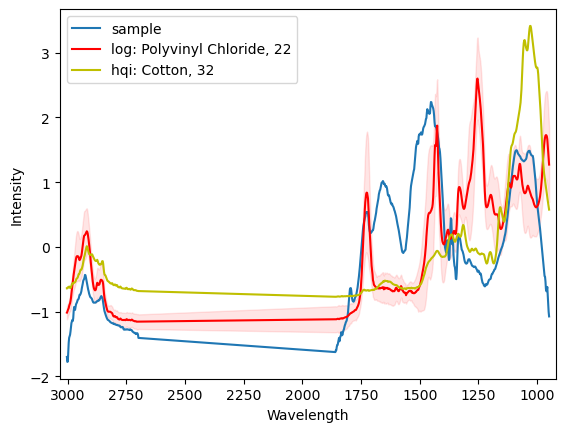

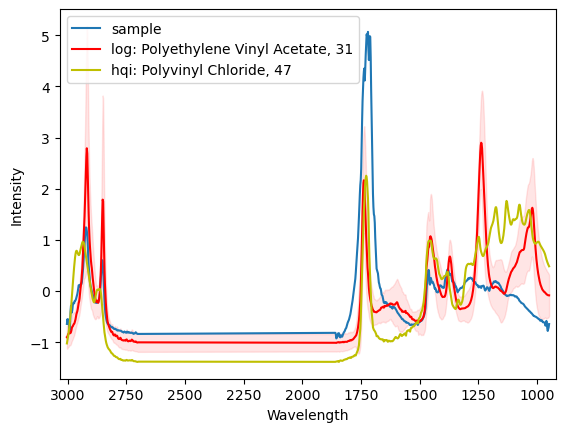

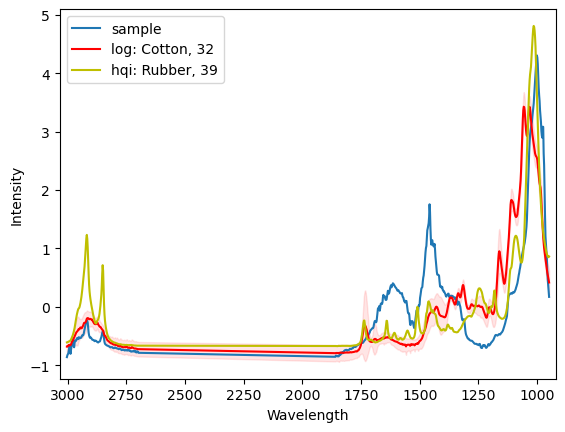

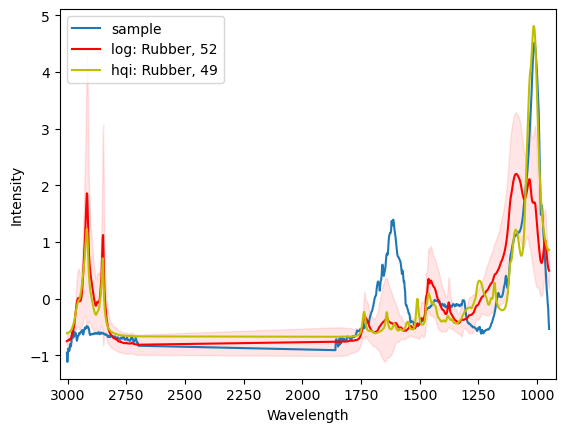

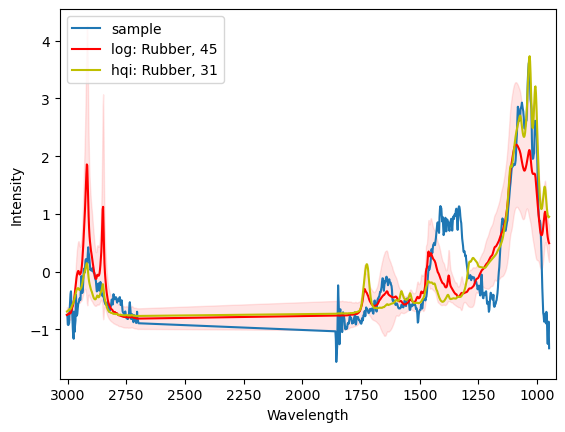

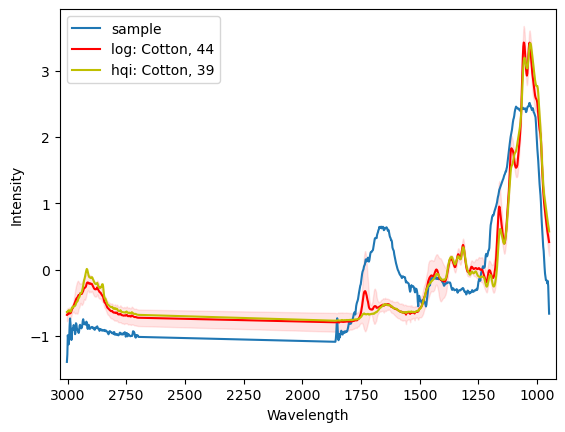

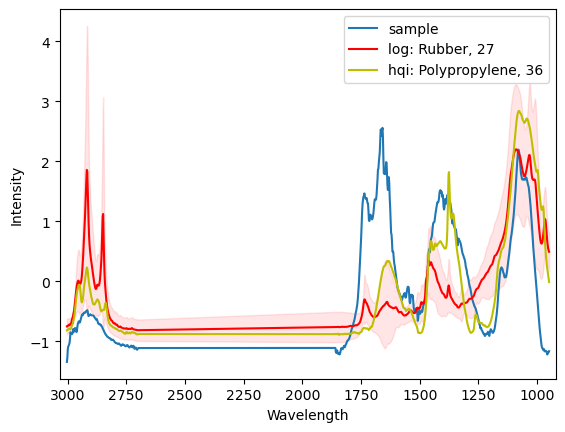

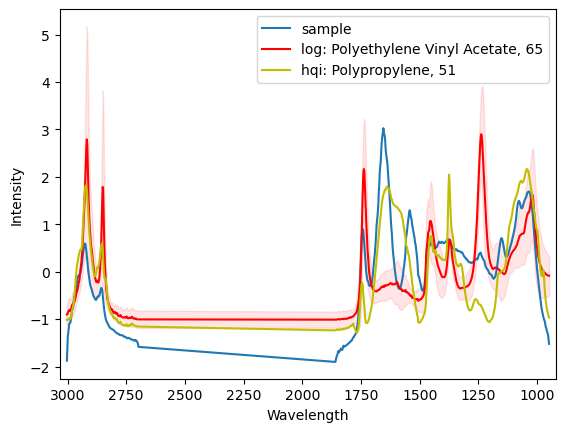

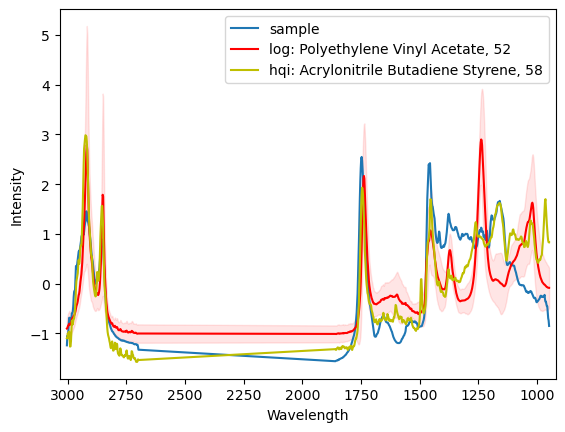

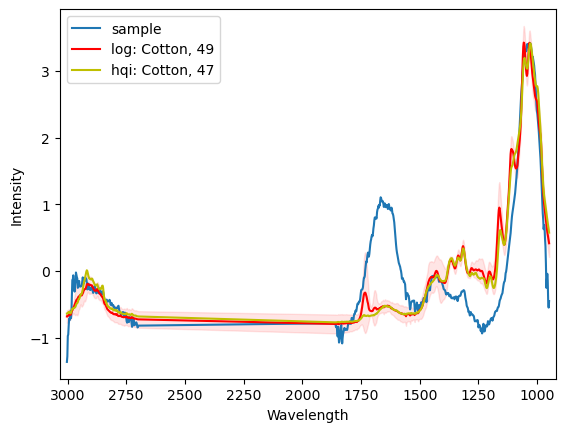

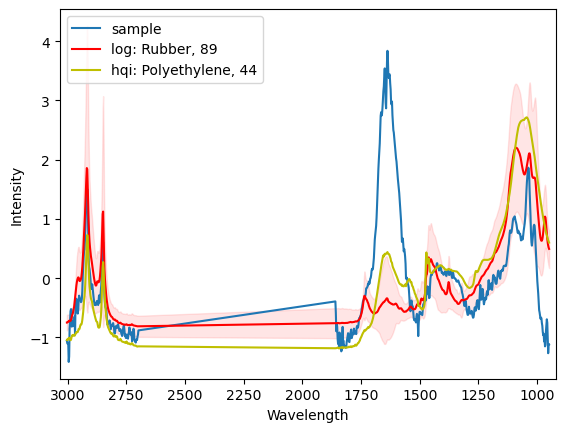

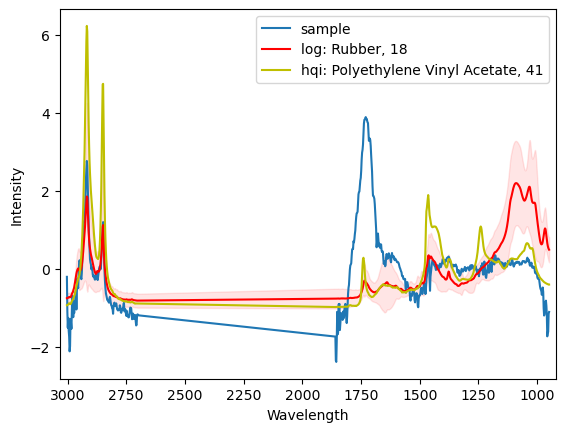

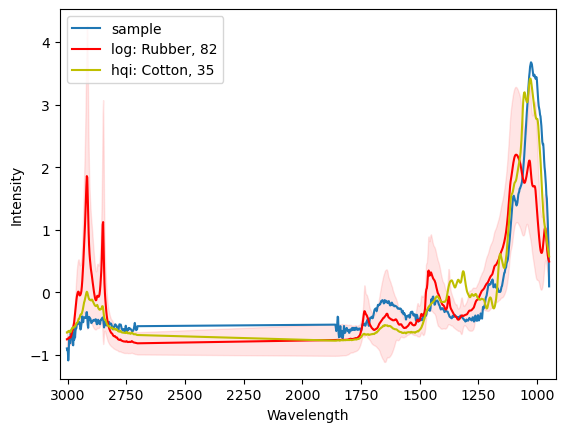

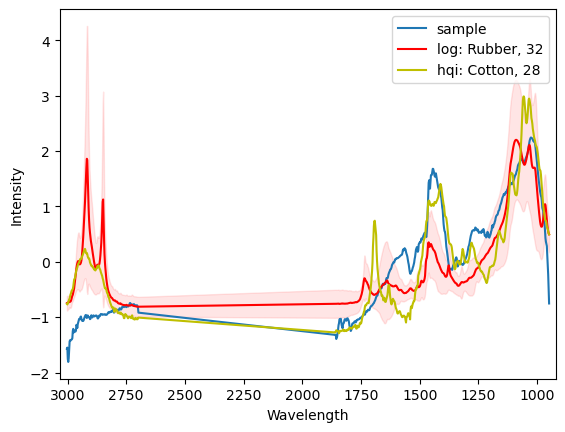

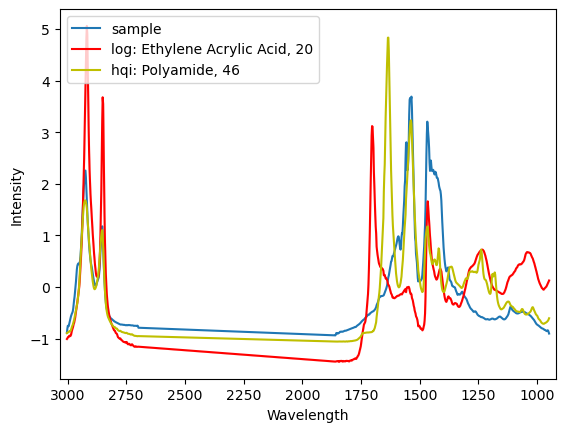

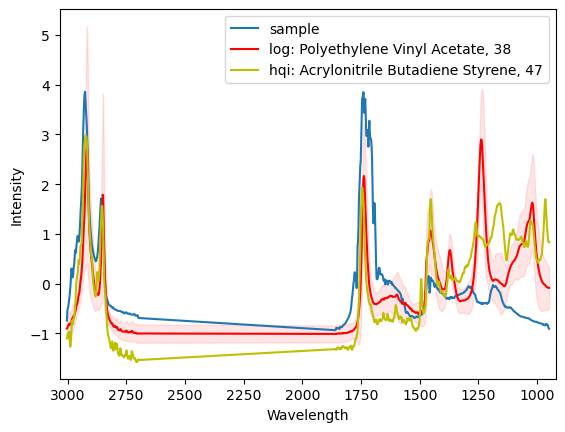

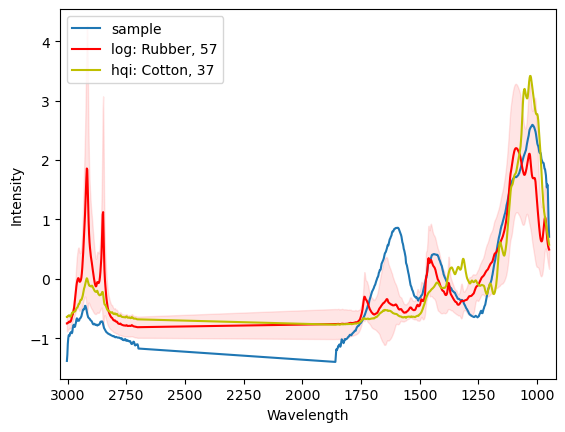

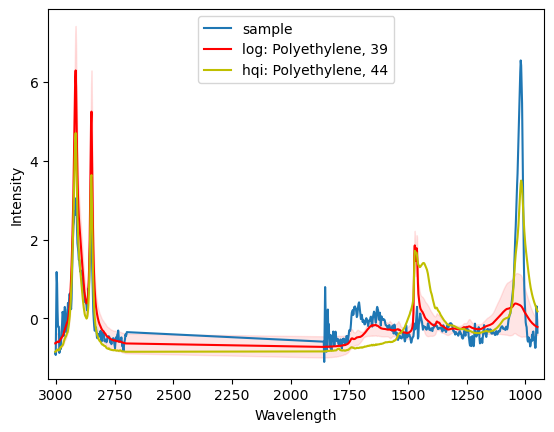

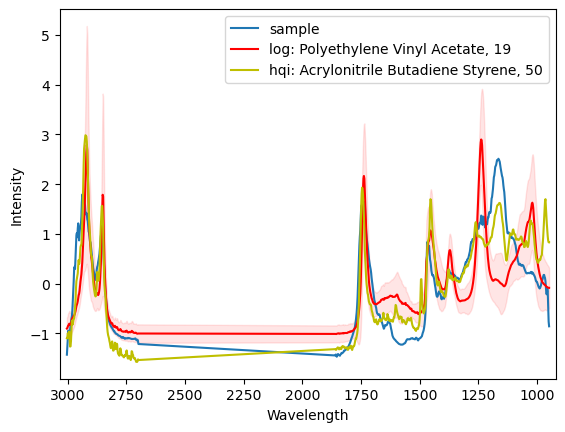

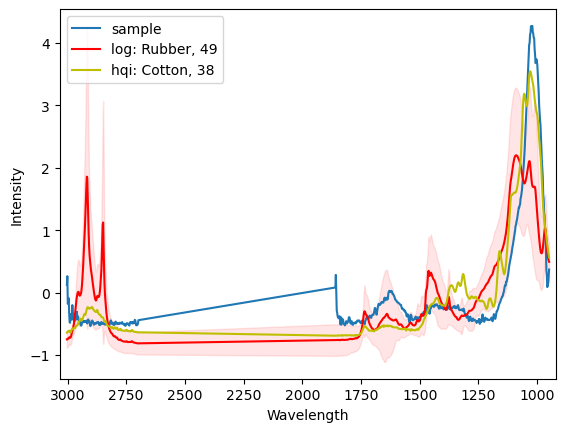

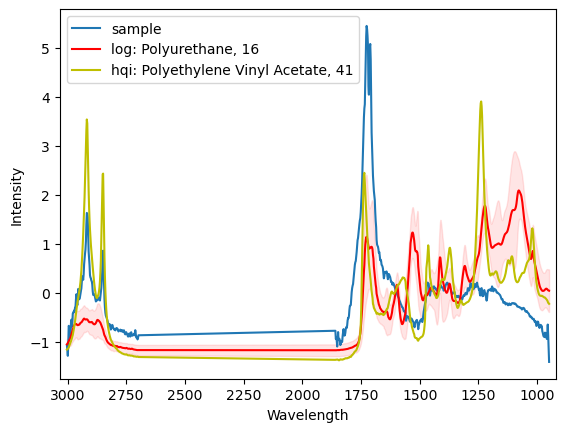

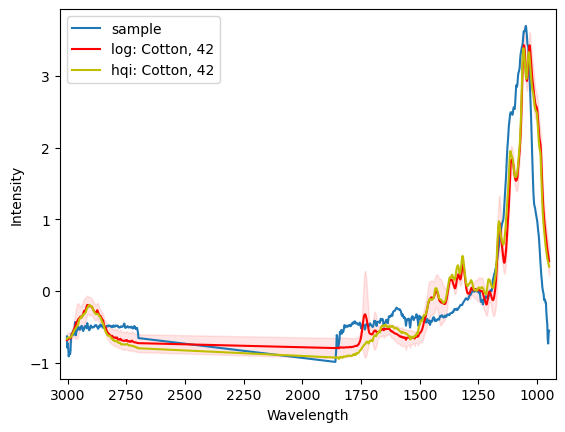

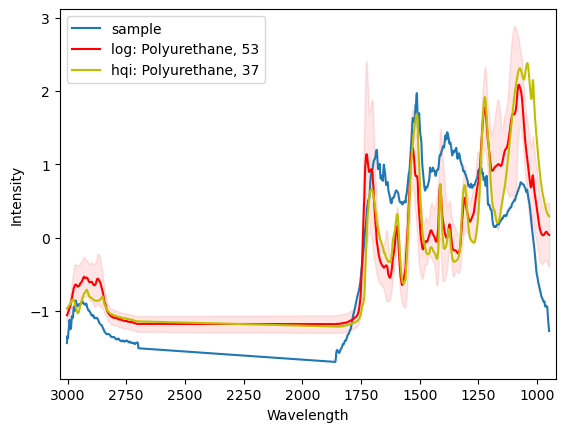

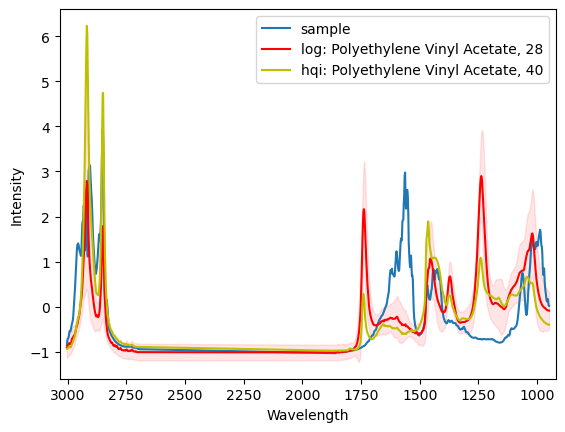

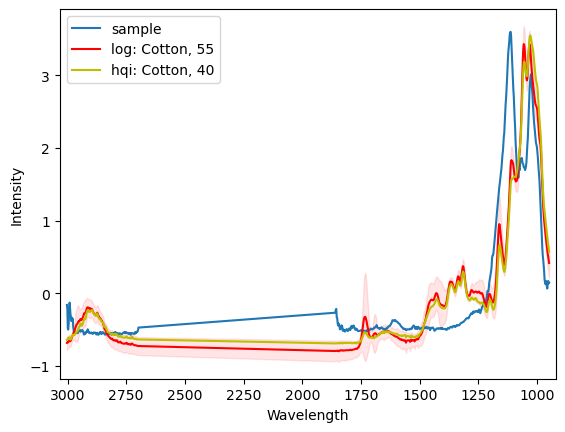

In [393]:
fig, ax = plt.subplots(layout='constrained')
#plt.show()
for i in np.argsort(distance_center_k_):
    s = spectra_data_np_norm[i]
    #if pred_prob[i] < .8 and pred_hqi[i] < .7:
    #    continue
    if std_2700_3000[i] < 0.06:
        #spectra_non_signal_id.append(spectra_data_int['file_name'][i])
        continue
    
    threshold = 27
    if distance_center_k_[i] > threshold:
        break
    #if pred_poly_diff[i] != pred_polymers_hqi_diff[i]:
        #spectra_non_signal_id.append(spectra_data_int['file_name'][i])
    #    continue
    #pred_match.append(pred_poly[i] == pred_polymers_hqi[i])
    #print(pred_poly[i], pred_prob[i])
    k = best_match_diff[i]
    #print(i, distance_center_k_[i])
    #print(i, corr_center_k_[i])
    #print(spectra_data_int.iloc[i,0])
    #print('logistic regression: ' + pred_poly_diff[i], round(pred_prob_diff[i]*100))
    #print('                hqi: ' + pred_polymers_hqi_diff[i], round(pred_hqi_diff[i]*100))
    
    plt.plot((wl_list[idx_range]), s, label='sample')
    plt.plot((wl_list[idx_range]), x_train[y_train == pred_poly_diff[i]].mean(0), c='r', label='log: ' + pred_poly_diff[i] + ', ' + str(round(pred_prob_diff[i]*100)))
    plt.fill_between(wl_list[idx_range],
                 x_train[y_train == pred_poly_diff[i]].mean(0) - x_train[y_train == pred_poly_diff[i]].std(0),
                 x_train[y_train == pred_poly_diff[i]].mean(0) + x_train[y_train == pred_poly_diff[i]].std(0), 
                     color='r', alpha=.1)

    plt.plot((wl_list[idx_range]), x_train[k], c='y', label='hqi: ' + pred_polymers_hqi_diff[i]+ ', ' + str(round(pred_hqi_diff[i]*100)))
    #plt.plot(                     -X_train.loc[y_train_ == pred_poly[i],:].iloc[0,:].to_numpy())
    plt.legend()
    plt.ylabel('Intensity')
    plt.xlabel('Wavelength')
    plt.xlim(wl_list[idx_range].max()/.99, wl_list[idx_range].min()*.97)
    
    #if distance_center_k_[i] > threshold:
        #break
        #spectra_rejected_id.append(spectra_data_int['file_name'][i])
        #plt.savefig('Pilot_Phase_Field_Samples_results2/matches_rejected/' + spectra_data_int.iloc[i,0] +'.png')
    #else:
        #spectra_id.append(spectra_data_int['file_name'][i])
        #plt.show()
        #plt.savefig('Pilot_Phase_Field_Samples_results2/matches_acepted/' + spectra_data_int.iloc[i,0] +'.png')
    plt.show()

In [160]:
pred_match_log_diff = pred_poly_diff[~rejected]
pred_match_hqi_diff = pred_polymers_hqi_diff[~rejected]

pred_match_prob_log_diff = pred_prob_diff[~rejected]
pred_match_score_hqi_diff = pred_hqi_diff[~rejected]

In [161]:
#~rejected
spectra_id = spectra_data_int.loc[~rejected, 'file_name'].to_numpy()

In [162]:
spectra_non_signal_id = spectra_data_int.loc[(std_2700_3000 <= 0.06), 'file_name'].to_numpy()
spectra_rejected_id = spectra_data_int.loc[np.logical_and(std_2700_3000 > 0.06,
                                                         distance_center_k_ >= 27), 'file_name'].to_numpy()

In [376]:
data_summary = pd.concat([#spectra_data.groupby(['school', 'run']).count().iloc[:,0:1], 
                          spectra_data_bg.groupby(['school', 'run']).count().iloc[:,0:1],
                          pd.concat([(pd.DataFrame({'# samples':1, 
                                       'id':spectra_non_signal_id})
                         .merge(spectra_data.iloc[:,-4:])
                         .loc[:,['# samples', 'school', 'run']]).groupby(['school', 'run']).sum(),
                        (pd.DataFrame({'# samples':1, 
                                       'id':spectra_rejected_id})
                         .merge(spectra_data.iloc[:,-4:])
                         .loc[:,['# samples', 'school', 'run']]).groupby(['school', 'run']).sum()], 1),
    
                        (pd.DataFrame({'polymer':pred_match_log_diff, 
                                                             'polymer_hqi':pred_match_hqi_diff, 
                                                   '# samples':1, 
                                                   'id':spectra_id})
                                     .query('polymer != polymer_hqi')        
                                     .merge(spectra_data.iloc[:,-4:])
                                     .loc[:,['polymer', '# samples', 'school', 'run']]
                                     .groupby(['school', 'run']).sum()
                                     ),
                          (pd.DataFrame({'polymer':pred_match_log_diff, 
                                         'polymer_hqi':pred_match_hqi_diff, 
                               '# samples':1, 
                               'id':spectra_id})
                 .query('polymer == polymer_hqi')        
                 .merge(spectra_data.iloc[:,-4:])
                 .loc[:,['polymer', '# samples', 'school', 'run']]
                 .groupby(['school', 'run']).sum()
                 )
                         ], 1)
data_summary = pd.concat([data_summary.sum(1), data_summary], 1)
data_summary.columns = ['total','background', 'no-signal 2700-3000', 'rejected', 'hits_diff', 'hits_double_match']
data_summary.to_csv('Pilot_Phase_Field_Samples_results2/data_summary_double_match.csv')
data_summary

total  background  no-signal 2700-3000  rejected  hits_diff  \
school   run                                                                 
Daycroft Run1  103.0          46                   12        38        5.0   
         Run2   65.0          28                    6        31        NaN   
         Run3  105.0          38                    5        62        NaN   
FHS      Run1   99.0          41                   16        37        2.0   
         Run2  106.0          27                   20        46        9.0   
         Run3  105.0          47                   14        34        4.0   
IAO      Run1  104.0          66                    1        32        2.0   
         Run2  105.0          57                    5        41        1.0   
         Run3  102.0          50                    1        49        1.0   
ICB      Run1  100.0          31                   19        49        1.0   
         Run2  101.0          48                   13        34        3.0   
         Run3  106.0          30                   15        58        1.0   

               hits_double_match  
school   run                      
Daycroft Run1                2.0  
         Run2                NaN  
         Run3                NaN  
FHS      Run1                3.0  
         Run2                4.0  
         Run3                6.0  
IAO      Run1                3.0  
         Run2                1.0  
         Run3                1.0  
ICB      Run1                NaN  
         Run2                3.0  
         Run3                2.0

In [377]:
pd.DataFrame(data_summary.sum(0))#[1:]#.sum()

,0
total,1201.0
background,509.0
no-signal 2700-3000,127.0
rejected,511.0
hits_diff,29.0
hits_double_match,25.0


In [298]:
results_log_diff = pd.DataFrame({'polymer':pred_match_log_diff, '# samples':1}).groupby('polymer').sum()
results_hqi_diff = pd.DataFrame({'polymer':pred_match_hqi_diff, '# samples':1}).groupby('polymer').sum()
#results_log_diff = np.round(100 * results_log_diff / results_log_diff.sum())

results_log_diff = results_log_diff.reset_index()
results_hqi_diff = results_hqi_diff.reset_index()

results_diff = results_log_diff.merge(results_hqi_diff, on='polymer', how='outer')
results_diff.columns = ['polymer', '# samples log', '# samples hqi']
results_diff = results_diff.append({'polymer':'Rejected', 
                                    '# samples log':rejected.sum(),
                                    '# samples hqi':rejected.sum()}, 
                        ignore_index=True)
results_diff.to_csv('Pilot_Phase_Field_Samples_results2/matches_distribution.csv')
results_diff

,polymer,# samples log,# samples hqi
0,Cotton,7.0,12.0
1,Ethylene Acrylic Acid,1.0,NaN
2,Polyamide,1.0,2.0
3,Polyethylene,7.0,9.0
4,Polyethylene Terephthalate,1.0,NaN
5,Polyethylene Vinyl Acetate,11.0,9.0
6,Polystyrene,1.0,1.0
7,Polyurethane,2.0,1.0
8,Polyvinyl Chloride,1.0,2.0
9,Rubber,22.0,11.0


In [207]:
results_diff.iloc[:,1:].apply(np.isnan, axis=1)

,# samples log,# samples hqi
0,False,False
1,False,True
2,False,False
3,False,False
4,False,True
5,False,False
6,False,False
7,False,False
8,False,False
9,False,False


In [236]:
results_diff_dm_1 = pd.read_csv('Pilot_Phase_Field_Samples_results/matches_distribution_double_match.csv')
del results_diff_dm_1['Unnamed: 0']

In [324]:
results_diff_dm = pd.DataFrame({'polymer_log':pred_match_log_diff, 
              'polymer_hqi':pred_match_hqi_diff, 
              '# samples':1}).query('polymer_log == polymer_hqi')
results_diff_dm['polymer'] = results_diff_dm['polymer_log']
results_diff_dm = results_diff_dm.groupby('polymer').sum().reset_index()
results_diff_dm.to_csv('Pilot_Phase_Field_Samples_results2/matches_distribution_double_match.csv')
results_diff_dm

,polymer,# samples
0,Cotton,6
1,Polyamide,1
2,Polyethylene,6
3,Polyethylene Vinyl Acetate,2
4,Polystyrene,1
5,Polyurethane,1
6,Rubber,8


In [254]:
results_diff_dm_joint = results_diff_dm_1.merge(results_diff_dm, on='polymer', how='outer')
results_diff_dm_joint.columns = ['polymer', 'substrate 1 %', 'substrate 2 %']
results_diff_dm_joint['substrate 1 %'] = np.round(100 * results_diff_dm_joint['substrate 1 %'] / results_diff_dm_joint['substrate 1 %'].sum())
results_diff_dm_joint['substrate 2 %'] = np.round(100 * results_diff_dm_joint['substrate 2 %'] / results_diff_dm_joint['substrate 2 %'].sum())
results_diff_dm_joint

,polymer,substrate 1 %,substrate 2 %
0,Cellulose Acetate,3.0,NaN
1,Cotton,24.0,24.0
2,Polyamide,14.0,4.0
3,Polyethylene,16.0,24.0
4,Polyethylene Vinyl Acetate,3.0,8.0
5,Rubber,41.0,32.0
6,Polystyrene,NaN,4.0
7,Polyurethane,NaN,4.0


In [285]:

{'subs_1':results_diff_dm_joint.iloc[:,1].to_numpy(),
'subs_2':results_diff_dm_joint.iloc[:,2].to_numpy()}
list(results_diff_dm_joint['polymer'])

['Cellulose Acetate',
 'Cotton',
 'Polyamide',
 'Polyethylene',
 'Polyethylene Vinyl Acetate',
 'Rubber',
 'Polystyrene',
 'Polyurethane']

In [286]:
polymers =['Cellulose Acetate',
 'Cotton',
 'Polyamide',
 'Polyethylene',
 'PVA',
 'Rubber',
 'Polystyrene',
 'Polyurethane']

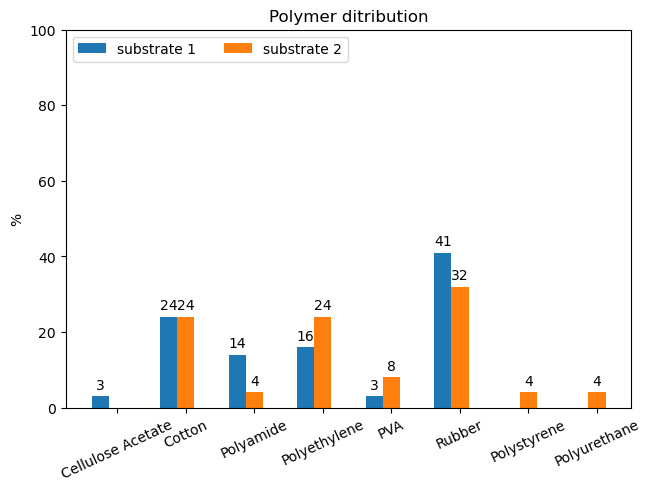

In [296]:
import matplotlib.pyplot as plt
import numpy as np

#species = ("Adelie", "Chinstrap", "Gentoo")
#penguin_means = {
#    'Bill Depth': (18.35, 18.43, 14.98),
#    'Bill Length': (38.79, 48.83, 47.50),
#    'Flipper Length': (189.95, 195.82, 217.19),
#}

species =polymers
penguin_means = {'substrate 1':results_diff_dm_joint.iloc[:,1].to_numpy(),
'substrate 2':results_diff_dm_joint.iloc[:,2].to_numpy()}

x = np.arange(len(species))  # the label locations
width = 0.25  # the width of the bars
multiplier = 0

fig, ax = plt.subplots(layout='constrained')

for attribute, measurement in penguin_means.items():
    offset = width * multiplier
    rects = ax.bar(x + offset, measurement, width, label=attribute)
    ax.bar_label(rects, padding=3)
    multiplier += 1

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('%')
ax.set_title('Polymer ditribution')
ax.set_xticks(x + width, species)
ax.legend(loc='upper left', ncols=3)
ax.set_ylim(0, 100)
plt.xticks(rotation = 25)

plt.show()

In [64]:
spectra_data.iloc[:,-4:]

,id,school,run,sample_id
0,ICB_Run2_1,ICB,Run2,1
1,ICB_Run2_2,ICB,Run2,2
2,ICB_Run2_3,ICB,Run2,3
3,ICB_Run2_4,ICB,Run2,4
4,ICB_Run2_5,ICB,Run2,5
...,...,...,...,...
1450,IAO_Run1_118,IAO,Run1,118
1451,IAO_Run1_119,IAO,Run1,119
1452,IAO_Run1_120,IAO,Run1,120
1453,IAO_Run1_121,IAO,Run1,121


In [320]:
table_results = (pd.DataFrame({'polymer_log':pred_match_log_diff, 
                               'prob log':pred_match_prob_log_diff, 
               '# samples':1, 
               'id':spectra_id})
 .merge(pd.DataFrame({'polymer_hqi':pred_match_hqi_diff, 
                      'hqi':pred_match_score_hqi_diff, 
               'id':spectra_id}), on='id')
 .merge(spectra_data.iloc[:,-4:])
 .loc[:,['polymer_log', 'polymer_hqi','prob log', 'hqi', '# samples', 'school', 'run','sample_id']]
 .groupby(['school', 'run', 'sample_id', 'polymer_log', 'polymer_hqi']).sum()).reset_index().iloc[:,:-1]
table_results.to_csv('Pilot_Phase_Field_Samples_results2/table_results.csv')
table_results

,school,run,sample_id,polymer_log,polymer_hqi,prob log,hqi
0,Daycroft,Run1,15,Polyethylene,Polyethylene Vinyl Acetate,0.386856,0.731786
1,Daycroft,Run1,20,Polyethylene Vinyl Acetate,Acrylonitrile Butadiene Styrene,0.519885,0.584086
2,Daycroft,Run1,34,Polyethylene Vinyl Acetate,Polyethylene Vinyl Acetate,0.407570,0.817056
3,Daycroft,Run1,38,Rubber,Polyethylene,0.460187,0.577433
4,Daycroft,Run1,47,Cotton,Cotton,0.494051,0.467064
5,Daycroft,Run1,91,Polyurethane,Polyethylene Vinyl Acetate,0.158625,0.405484
6,Daycroft,Run1,93,Polyethylene Vinyl Acetate,Acrylonitrile Butadiene Styrene,0.190074,0.498120
7,FHS,Run1,7,Rubber,Polyethylene Vinyl Acetate,0.182765,0.406964
8,FHS,Run1,31,Polyamide,Polyamide,0.776354,0.594106
9,FHS,Run1,48,Cotton,Cotton,0.751908,0.585005


In [321]:
table_results_dm = table_results.query('polymer_log==polymer_hqi')
table_results_dm.to_csv('Pilot_Phase_Field_Samples_results2/table_results_double_match.csv')
table_results_dm

,school,run,sample_id,polymer_log,polymer_hqi,prob log,hqi
2,Daycroft,Run1,34,Polyethylene Vinyl Acetate,Polyethylene Vinyl Acetate,0.407570,0.817056
4,Daycroft,Run1,47,Cotton,Cotton,0.494051,0.467064
8,FHS,Run1,31,Polyamide,Polyamide,0.776354,0.594106
9,FHS,Run1,48,Cotton,Cotton,0.751908,0.585005
10,FHS,Run1,58,Cotton,Cotton,0.554400,0.400463
17,FHS,Run2,48,Cotton,Cotton,0.572348,0.500383
19,FHS,Run2,69,Rubber,Rubber,0.523507,0.487831
21,FHS,Run2,73,Rubber,Rubber,0.403142,0.697422
22,FHS,Run2,74,Rubber,Rubber,0.610338,0.952731
26,FHS,Run3,16,Rubber,Rubber,0.905920,0.793825


In [317]:
spectra_data.merge(table_results, on=['school','run','sample_id']).to_csv('Pilot_Phase_Field_Samples_results2/spectra_matches.csv')


In [323]:
spectra_data.merge(table_results_dm, on=['school','run','sample_id']).to_csv('Pilot_Phase_Field_Samples_results2/spectra_matches_double_match.csv')
